# Módulo 08 : Buenas prácticas agrícolas

## 1. Objetivo

Describir las prácticas agrícolas declaradas por las UA de la ENA 2025 y comparar la rotación entre regiones naturales y departamentos. Los años de `P302A_3` describen la antigüedad de la práctica, mas no la duración de cosecha.

El módulo 03 se utiliza como fuente auxiliar de cultivos, sin modificarlo. Los cálculos principales conservan su población y sus filtros originales. La selección, las fechas y el estudio de cosechas pertenecen al módulo 03.

## 2. Lectura

### 2.1. Importación de librerías

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

### 2.2. Lectura de datos y diccionario

Leemos el archivo Parquet del módulo 08 y su diccionario de variables para realizar los análisis.

Para reproducir las salidas, coloca el notebook en la carpeta de notebooks del proyecto, de modo que `../data/raw/` contenga `08_CAP300AB.parquet`, `03_CAP200AB.parquet` y `DICC_ENA_2025.xlsx`. El entorno de Python necesita pandas, Matplotlib, un motor Parquet como pyarrow y openpyxl para leer el diccionario.


In [2]:
# Módulo 08
df_buenas_practicas = pd.read_parquet("../data/raw/08_CAP300AB.parquet")

# Leer el diccionario del módulo 08
df_diccionario_08 = pd.read_excel("../data/raw/DICC_ENA_2025.xlsx", sheet_name="08_CAP300AB")

In [3]:
# Comprobar la lectura del módulo 08
print("Archivo cargado como:", type(df_buenas_practicas).__name__)
print("Filas y columnas:", df_buenas_practicas.shape)

# Comprobar la lectura del diccionario
print("Diccionario cargado como:", type(df_diccionario_08).__name__)

Archivo cargado como: DataFrame
Filas y columnas: (39729, 111)
Diccionario cargado como: DataFrame


In [4]:
print("Filas del diccionario:", len(df_diccionario_08))
print("Columnas del diccionario:", df_diccionario_08.columns.tolist())

Filas del diccionario: 238
Columnas del diccionario: ['Nº', 'NOMBRE DE LA VARIABLE', 'DESCRIPCIÓN DE LAS VARIABLES', 'VALOR', 'TIPO', 'LONGITUD', 'DECIMAL']


## 3. Inspección estructural

### 3.1. Primeras filas y dimensiones

Observamos los primeros registros y dimensiones del módulo 08.


In [5]:
# Primeras filas
display(df_buenas_practicas.head())

# Dimensiones
print("\nFilas y columnas:", df_buenas_practicas.shape)

,ANIO,CCDD,NOMBREDD,CCPP,NOMBREPV,CCDI,NOMBREDI,NSEGM,ID_PROD,UA,...,P327B,P328B,P329B_1,P329B_2,P329B_3,P329B_4,P329B_5,P329B_6,P330B,OMICAP300
0,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
1,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
2,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,3,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
3,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,4,4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
4,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30002,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,



Filas y columnas: (39729, 111)


### 3.2. Columnas, tipos y valores no nulos

Revisamos la estructura del archivo y la disponibilidad de sus variables.


In [6]:
print("Columnas:", df_buenas_practicas.columns.tolist())
print("\n ")

# Tipos y valores no nulos
df_buenas_practicas.info(verbose=True, show_counts=True)

Columnas: ['ANIO', 'CCDD', 'NOMBREDD', 'CCPP', 'NOMBREPV', 'CCDI', 'NOMBREDI', 'NSEGM', 'ID_PROD', 'UA', 'RESFIN', 'REGION', 'ESTRATO', 'FACTOR_PRODUCTOR', 'CODIGO', 'P101A', 'P142_1', 'P142_2', 'P142_3', 'P301A_1', 'P302A_1', 'P301A_2', 'P302A_2', 'P301A_3', 'P302A_3', 'P301A_4', 'P302A_4', 'P301A_4A', 'P302A_4A', 'P301A_4B', 'P302A_4B', 'P301A_4C', 'P302A_4C', 'P301A_5', 'P302A_5', 'P301A_6', 'P302A_6', 'P301A_7', 'P302A_7', 'P301A_8', 'P302A_8', 'P301A_9', 'P302A_9', 'P301A_10', 'P302A_10', 'P301A_11', 'P302A_11', 'P301A_12', 'P302A_12', 'P301A_12A', 'P302A_12A', 'P301A_12B', 'P302A_12B', 'P301A_12C', 'P302A_12C', 'P301A_13', 'P302A_13', 'P301A_14', 'P302A_14', 'P301A_15', 'P302A_15', 'P301A_16', 'P302A_16', 'P301A_17', 'P302A_17', 'P303B', 'P304B', 'P305B', 'P306B', 'P307B', 'P308B', 'P309B', 'P310B', 'P311B', 'P312B', 'P313B', 'P314B', 'P315B', 'P316B', 'P317B', 'P318B', 'P319B', 'P320B', 'P321B', 'P322B', 'P323B', 'P324B', 'P325B_1', 'P325B_2', 'P325B_3', 'P325B_4', 'P325B_5', 'P

## 4. Unidad de registro e identificadores


### 4.1. Identificación

El proyecto propone una llave de siete campos para relacionar módulos. Comprobamos cuáles están disponibles aquí. `NSEGM` se considera una llave candidata, sin asumir que equivale a `CLUSTER`.


In [7]:
# Llave establecida en el proyecto
llave_oficial = ["ANIO", "CCDD", "CCPP", "CCDI", "CLUSTER", "ID_PROD", "UA"]

# Identificadores disponibles en el módulo 08
print("Columnas del módulo:", df_buenas_practicas.columns.tolist())

# Comparar la llave oficial con las columnas del módulo
print("\nCampos de la llave presentes:", [col for col in llave_oficial if col in df_buenas_practicas.columns])
print("Campos de la llave ausentes:", [col for col in llave_oficial if col not in df_buenas_practicas.columns])

Columnas del módulo: ['ANIO', 'CCDD', 'NOMBREDD', 'CCPP', 'NOMBREPV', 'CCDI', 'NOMBREDI', 'NSEGM', 'ID_PROD', 'UA', 'RESFIN', 'REGION', 'ESTRATO', 'FACTOR_PRODUCTOR', 'CODIGO', 'P101A', 'P142_1', 'P142_2', 'P142_3', 'P301A_1', 'P302A_1', 'P301A_2', 'P302A_2', 'P301A_3', 'P302A_3', 'P301A_4', 'P302A_4', 'P301A_4A', 'P302A_4A', 'P301A_4B', 'P302A_4B', 'P301A_4C', 'P302A_4C', 'P301A_5', 'P302A_5', 'P301A_6', 'P302A_6', 'P301A_7', 'P302A_7', 'P301A_8', 'P302A_8', 'P301A_9', 'P302A_9', 'P301A_10', 'P302A_10', 'P301A_11', 'P302A_11', 'P301A_12', 'P302A_12', 'P301A_12A', 'P302A_12A', 'P301A_12B', 'P302A_12B', 'P301A_12C', 'P302A_12C', 'P301A_13', 'P302A_13', 'P301A_14', 'P302A_14', 'P301A_15', 'P302A_15', 'P301A_16', 'P302A_16', 'P301A_17', 'P302A_17', 'P303B', 'P304B', 'P305B', 'P306B', 'P307B', 'P308B', 'P309B', 'P310B', 'P311B', 'P312B', 'P313B', 'P314B', 'P315B', 'P316B', 'P317B', 'P318B', 'P319B', 'P320B', 'P321B', 'P322B', 'P323B', 'P324B', 'P325B_1', 'P325B_2', 'P325B_3', 'P325B_4', 'P

In [8]:
# Llave candidata
llave_08 = ["ANIO", "CCDD", "CCPP", "CCDI", "NSEGM", "ID_PROD", "UA"]

print("Llave candidata:", llave_08)
print("Campos disponibles:", all(col in df_buenas_practicas.columns for col in llave_08))

Llave candidata: ['ANIO', 'CCDD', 'CCPP', 'CCDI', 'NSEGM', 'ID_PROD', 'UA']
Campos disponibles: True


### 4.2. Valores faltantes

Revisamos los identificadores incompletos y verificamos si existen combinaciones repetidas de la llave candidata y de la identificación de UA.


In [9]:
# Valores nulos por identificador
print(df_buenas_practicas[llave_08].isna().sum())

# Registros con algún identificador faltante
print("\nRegistros incompletos:", df_buenas_practicas[llave_08].isna().any(axis=1).sum())

ANIO          0
CCDD       1343
CCPP       1343
CCDI       1343
NSEGM         0
ID_PROD       0
UA            0
dtype: int64

Registros incompletos: 1343


In [10]:
# Registros con todos los identificadores presentes
df_llave_completa = df_buenas_practicas.dropna(subset=llave_08)

# Combinaciones repetidas de la llave
print("Registros con llave completa:", len(df_llave_completa))
print("Combinaciones repetidas:", df_llave_completa.duplicated(subset=llave_08).sum())

Registros con llave completa: 38386
Combinaciones repetidas: 0


In [11]:
# Identificamos de UA sin ID_PROD
llave_ua = ["ANIO", "CCDD", "CCPP", "CCDI", "NSEGM", "UA"]

# Verificamos repetición
repeticiones_ua = df_llave_completa.duplicated(subset=llave_ua, keep=False)

print("Filas con UA repetida:", repeticiones_ua.sum())

# Mostrar registros repetidos
if repeticiones_ua.any():
    display(df_llave_completa.loc[repeticiones_ua, llave_08].head(10))

Filas con UA repetida: 0


### 4.3. Delimitación de registros

Excluimos los registros sin departamento identificado y revisamos el año y el resultado final de la encuesta.


In [12]:
# Registros sin departamento
sin_departamento = df_buenas_practicas["NOMBREDD"].isna().sum()

# Copia para los siguientes análisis
df_analisis = df_buenas_practicas[df_buenas_practicas["NOMBREDD"].notna()].copy()

print("Registros sin departamento:", sin_departamento)
print("Registros disponibles para análisis:", len(df_analisis))

Registros sin departamento: 1343
Registros disponibles para análisis: 38386


In [13]:
print("Años:")
print(df_analisis["ANIO"].value_counts(dropna=False))

print("\nResultado final de encuesta:")
print(df_analisis["RESFIN"].value_counts(dropna=False))

Años:
ANIO
2025    38386
Name: count, dtype: int64

Resultado final de encuesta:
RESFIN
1    38386
Name: count, dtype: int64


## 5. Reconocimiento mediante el diccionario

### 5.1. Consulta de variables

Consultamos las descripciones y los valores de las variables seleccionadas en el diccionario.


In [14]:
# Columnas del diccionario
columnas_dic = ["NOMBRE DE LA VARIABLE", "DESCRIPCIÓN DE LAS VARIABLES", "VALOR"]

# Variables que se consultarán
codigos = [
    "REGION", "NSEGM", "ID_PROD", "UA",
    "P301A_1", "P301A_2", "P301A_3",
    "P301A_9", "P301A_10", "P301A_12A", "P301A_12B",
    "P301A_14", "P301A_15", "P302A_3"
]

In [15]:
# Consultamos las variables y sus filas cercanas
for codigo in codigos:
    indices = df_diccionario_08.index[df_diccionario_08["NOMBRE DE LA VARIABLE"].eq(codigo)]
    print("\nCódigo:", codigo)

    if len(indices):
        i = indices[0]
        display(df_diccionario_08.loc[max(0, i-2):min(len(df_diccionario_08)-1, i+2), columnas_dic])
    else:
        print("No aparece en el diccionario.")


Código: REGION


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
12,NaN,NaN,2 Incompleta
13,NaN,NaN,1 Costa
14,REGION,REGIÓN NATURAL,2 Sierra
15,NaN,NaN,3 Selva
16,ESTRATO,ESTRATO MUESTRAL,NaN



Código: NSEGM


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
5,CCDI,Código del Distrito,NaN
6,NOMBREDI,Nombre del Distrito,NaN
7,NSEGM,NÚMERO CORRELATIVO EN SECUENCIA,NaN
8,NaN,SERPENTIN POR REGIÓN,NaN
9,ID_PROD,Identificador de la Unidad Agropecuaria,NaN



Código: ID_PROD


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
7,NSEGM,NÚMERO CORRELATIVO EN SECUENCIA,NaN
8,NaN,SERPENTIN POR REGIÓN,NaN
9,ID_PROD,Identificador de la Unidad Agropecuaria,NaN
10,UA,Unidad Agropecuaria N°,NaN
11,RESFIN,Resultado FINAL de la encuesta,1 Completa


... (18 outputs left out)


Código: P301A_15


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
126,NaN,"COMO PRODUCTOR INDEPENDIENTE, ¿LA EMPRESA/UD. ...",NaN
127,NaN,"DE: Usar plaguicidas como: Insecticidas, fungi...",NaN
128,P301A_15,NaN,1 Sí
129,NaN,NaN,2 No
130,NaN,¿HACE CUÁNTOS AÑOS LA REALIZA? Usar,NaN



Código: P302A_3


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
44,NaN,"COMO PRODUCTOR INDEPENDIENTE, ¿LA EMPRESA/UD. ...",1 Sí
45,P301A_3,DE: Rotar los cultivos para proteger el suelo?,2 No
46,P302A_3,¿HACE CUÁNTOS AÑOS LA REALIZA? Rotar los,NaN
47,NaN,cultivos para proteger el suelo?,NaN
48,NaN,"COMO PRODUCTOR INDEPENDIENTE, ¿LA EMPRESA/UD. ...",NaN


### 5.2. Catálogo de prácticas

Organizamos nueve prácticas agrícolas identificadas en el diccionario, considerando sus códigos, respuestas y condiciones de aplicación.


In [16]:
# Prácticas agrícolas seleccionadas
practicas = {
    "P301A_1": "Análisis de suelos",
    "P301A_2": "Mezclar la tierra con materia orgánica (rastrojos, estiércol, compost, humus, etc.)",
    "P301A_3": "Rotar los cultivos para proteger el suelo",
    "P301A_9": "Determinar la cantidad de agua que necesita su cultivo",
    "P301A_10": "Determinar cada cuánto tiempo debe regar su cultivo",
    "P301A_12A": "Análisis de agua",
    "P301A_12B": "Construcción de diques (SÓLO para la región Sierra)",
    "P301A_14": "Usar fertilizantes",
    "P301A_15": "Usar plaguicidas como: insecticidas, fungicidas, herbicidas, acaricidas, bactericidas, nematicidas, rodenticidas, molusquicidas, etc."
}

In [17]:
condicion_territorial = {"P301A_12B": "Solo Sierra (REGION = 2)"}

catalogo = pd.DataFrame([
    {
        "codigo": codigo,
        "significado": significado,
        "tipo": "categórica binaria",
        "respuestas": "1: Sí, 2: No",
        "condicion": condicion_territorial.get(codigo, "Sin restricción territorial indicada")
    }
    for codigo, significado in practicas.items()
])
display(catalogo)

,codigo,significado,tipo,respuestas,condicion
0,P301A_1,Análisis de suelos,categórica binaria,"1: Sí, 2: No",Sin restricción territorial indicada
1,P301A_2,Mezclar la tierra con materia orgánica (rastro...,categórica binaria,"1: Sí, 2: No",Sin restricción territorial indicada
2,P301A_3,Rotar los cultivos para proteger el suelo,categórica binaria,"1: Sí, 2: No",Sin restricción territorial indicada
3,P301A_9,Determinar la cantidad de agua que necesita su...,categórica binaria,"1: Sí, 2: No",Sin restricción territorial indicada
4,P301A_10,Determinar cada cuánto tiempo debe regar su cu...,categórica binaria,"1: Sí, 2: No",Sin restricción territorial indicada
5,P301A_12A,Análisis de agua,categórica binaria,"1: Sí, 2: No",Sin restricción territorial indicada
6,P301A_12B,Construcción de diques (SÓLO para la región Si...,categórica binaria,"1: Sí, 2: No",Solo Sierra (REGION = 2)
7,P301A_14,Usar fertilizantes,categórica binaria,"1: Sí, 2: No",Sin restricción territorial indicada
8,P301A_15,"Usar plaguicidas como: insecticidas, fungicida...",categórica binaria,"1: Sí, 2: No",Sin restricción territorial indicada


### 5.3. Condiciones de aplicación

Según las indicaciones del diccionario, verificamos las condiciones de aplicación de `P301A_12B` y `P302A_3`.


In [18]:
# Respuestas de P301A_12B por región natural
tabla_sierra = pd.crosstab(
    df_analisis["REGION"],
    df_analisis["P301A_12B"],
    dropna=False
)
display(tabla_sierra)

# Respuestas registradas fuera de Sierra
fuera_sierra = df_analisis[
    (df_analisis["REGION"] != 2) &
    (df_analisis["P301A_12B"].notna())
]

print("\nRespuestas fuera de Sierra:", len(fuera_sierra))

P301A_12B,1.0,2.0,NaN
REGION,,,
1,0,6,8747
2,86,22335,0
3,0,1,7211



Respuestas fuera de Sierra: 7


In [19]:
# Relación entre rotación de cultivos y años reportados
tabla_rotacion = pd.crosstab(
    df_analisis["P301A_3"],
    df_analisis["P302A_3"].notna(),
    dropna=False
)
tabla_rotacion.columns = ["Sin años registrados", "Años registrados"]
display(tabla_rotacion)

# Valores de años entre quienes respondieron Sí
anios_rotacion = df_analisis.loc[
    df_analisis["P301A_3"] == 1, "P302A_3"
]

print("\nRespuestas Sí:", len(anios_rotacion))
print("Años registrados:", anios_rotacion.notna().sum())
print("Años faltantes:", anios_rotacion.isna().sum())

,Sin años registrados,Años registrados
P301A_3,,
1,0,20946
2,17440,0



Respuestas Sí: 20946
Años registrados: 20946
Años faltantes: 0


## 6. Disponibilidad


### 6.1. Frecuencias y valores nulos

Contamos las respuestas `Sí` (1), `No` (2), los nulos y otros códigos de cada práctica.


In [20]:
# Frecuencias de las prácticas seleccionadas
disponibilidad = []

for codigo, significado in practicas.items():
    elegibles = df_analisis[df_analisis["REGION"] == 2] if codigo == "P301A_12B" else df_analisis
    respuestas = elegibles[codigo]

    disponibilidad.append({
        "codigo": codigo,
        "significado": significado,
        "elegibles": len(elegibles),
        "si": (respuestas == 1).sum(),
        "no": (respuestas == 2).sum(),
        "nulos": respuestas.isna().sum(),
        "otros_codigos": (respuestas.notna() & ~respuestas.isin([1, 2])).sum()
    })
tabla_disponibilidad = pd.DataFrame(disponibilidad)
display(tabla_disponibilidad[["codigo", "si", "no", "nulos", "otros_codigos"]])

,codigo,si,no,nulos,otros_codigos
0,P301A_1,1243,37143,0,0
1,P301A_2,23307,15079,0,0
2,P301A_3,20946,17440,0,0
3,P301A_9,10451,27935,0,0
4,P301A_10,15126,23260,0,0
5,P301A_12A,333,38053,0,0
6,P301A_12B,86,22335,0,0
7,P301A_14,22104,16282,0,0
8,P301A_15,24253,14133,0,0


### 6.2. Respuestas válidas y elegibilidad

Calculamos el porcentaje de respuestas válidas (`1` o `2`) entre los registros elegibles. Para `P301A_12B`, el análisis corresponde únicamente a Sierra. Las respuestas registradas fuera de ella se revisan por separado.


In [21]:
# Respuestas válidas
tabla_disponibilidad["validas_1_2"] = tabla_disponibilidad["si"]+tabla_disponibilidad["no"]

# % de respuestas disponibles
tabla_disponibilidad["porcentaje_disponible"] = (
    tabla_disponibilidad["validas_1_2"] / tabla_disponibilidad["elegibles"]*100
).round(2)
display(tabla_disponibilidad[["codigo", "elegibles", "validas_1_2", "porcentaje_disponible"]])

,codigo,elegibles,validas_1_2,porcentaje_disponible
0,P301A_1,38386,38386,100.0
1,P301A_2,38386,38386,100.0
2,P301A_3,38386,38386,100.0
3,P301A_9,38386,38386,100.0
4,P301A_10,38386,38386,100.0
5,P301A_12A,38386,38386,100.0
6,P301A_12B,22421,22421,100.0
7,P301A_14,38386,38386,100.0
8,P301A_15,38386,38386,100.0


In [22]:
# Comprobamos si las frecuencias suman el total elegible
tabla_disponibilidad["total_contado"] = (
    tabla_disponibilidad["si"] +
    tabla_disponibilidad["no"] +
    tabla_disponibilidad["nulos"] +
    tabla_disponibilidad["otros_codigos"]
)
print("¿Las frecuencias coinciden con el total elegible?:",
      (tabla_disponibilidad["total_contado"] == tabla_disponibilidad["elegibles"]).all())

¿Las frecuencias coinciden con el total elegible?: True


## 7. Análisis descriptivos


### 7.1. Porcentajes de prácticas

**Pregunta:** ¿Qué proporción de las UA válidas declaró realizar cada práctica agrícola?

Se calcula el porcentaje de respuestas `Sí` sobre las respuestas válidas de cada práctica. `P301A_12B` tiene una base diferente porque solo corresponde a Sierra.


In [23]:
# Prácticas seleccionadas
resumen_practicas = tabla_disponibilidad[["codigo", "significado", "elegibles", "si", "no", "validas_1_2"]].copy()

# Porcentaje de respuestas "Sí"
resumen_practicas["porcentaje_si"] = (
    resumen_practicas["si"] / resumen_practicas["validas_1_2"].replace(0, float("nan")) * 100
).round(2)

display(resumen_practicas)

,codigo,significado,elegibles,si,no,validas_1_2,porcentaje_si
0,P301A_1,Análisis de suelos,38386,1243,37143,38386,3.24
1,P301A_2,Mezclar la tierra con materia orgánica (rastro...,38386,23307,15079,38386,60.72
2,P301A_3,Rotar los cultivos para proteger el suelo,38386,20946,17440,38386,54.57
3,P301A_9,Determinar la cantidad de agua que necesita su...,38386,10451,27935,38386,27.23
4,P301A_10,Determinar cada cuánto tiempo debe regar su cu...,38386,15126,23260,38386,39.40
5,P301A_12A,Análisis de agua,38386,333,38053,38386,0.87
6,P301A_12B,Construcción de diques (SÓLO para la región Si...,22421,86,22335,22421,0.38
7,P301A_14,Usar fertilizantes,38386,22104,16282,38386,57.58
8,P301A_15,"Usar plaguicidas como: insecticidas, fungicida...",38386,24253,14133,38386,63.18


### 7.2. Rotación por región natural

**Pregunta:** ¿Cómo varía la rotación de cultivos entre Costa, Sierra y Selva?

Para cada región, calculamos las respuestas `Sí` a `P301A_3` sobre el total válido de esa región.


In [24]:
# Respuestas válidas de rotación de cultivos
df_rotacion = df_analisis[df_analisis["P301A_3"].isin([1, 2])]

# Frecuencias por región natural
tabla_rotacion_region = pd.crosstab(df_rotacion["REGION"], df_rotacion["P301A_3"])

# Organizar columnas y regiones
tabla_rotacion_region = tabla_rotacion_region.reindex(index=[1, 2, 3], columns=[1, 2], fill_value=0)
tabla_rotacion_region.index = ["Costa", "Sierra", "Selva"]
tabla_rotacion_region.columns = ["Sí", "No"]

In [25]:
# Total de respuestas válidas por región
tabla_rotacion_region["Total válido"] = tabla_rotacion_region["Sí"] + tabla_rotacion_region["No"]

# Porcentaje de respuestas Sí
tabla_rotacion_region["Porcentaje Sí"] = (
    tabla_rotacion_region["Sí"] / tabla_rotacion_region["Total válido"] * 100
).round(2)
display(tabla_rotacion_region)

,Sí,No,Total válido,Porcentaje Sí
Costa,3649,5104,8753,41.69
Sierra,16571,5850,22421,73.91
Selva,726,6486,7212,10.07


### 7.3. Rotación por departamento

**Pregunta:** ¿Qué porcentaje de UA declaró realizar rotación de cultivos en cada departamento?

Se utilizan las respuestas válidas de `P301A_3` y se ordenan los departamentos por porcentaje de respuestas `Sí`.


In [26]:
# Frecuencias de rotación por departamento
tabla_rotacion_departamento = pd.crosstab(df_rotacion["NOMBREDD"], df_rotacion["P301A_3"])

# Organizar las respuestas
tabla_rotacion_departamento = tabla_rotacion_departamento.reindex(columns=[1, 2], fill_value=0)
tabla_rotacion_departamento.columns = ["Sí", "No"]

In [27]:
# Respuestas válidas por departamento
tabla_rotacion_departamento["Total válido"] = tabla_rotacion_departamento["Sí"]+tabla_rotacion_departamento["No"]

# % de respuestas Sí
tabla_rotacion_departamento["Porcentaje Sí"] = (
    tabla_rotacion_departamento["Sí"] / tabla_rotacion_departamento["Total válido"]*100
).round(2)

# Ordenar por porcentaje
tabla_rotacion_departamento = tabla_rotacion_departamento.sort_values("Porcentaje Sí", ascending=False)
display(tabla_rotacion_departamento)

,Sí,No,Total válido,Porcentaje Sí
NOMBREDD,,,,
PUNO,1974,336,2310,85.45
CUSCO,1873,363,2236,83.77
HUANCAVELICA,1063,212,1275,83.37
APURIMAC,1356,425,1781,76.14
AREQUIPA,1738,567,2305,75.40
AYACUCHO,2117,872,2989,70.83
LA LIBERTAD,1039,441,1480,70.20
MOQUEGUA,691,320,1011,68.35
ANCASH,2054,968,3022,67.97


In [28]:
# Comprobamos los totales
print("Registros analizados:", len(df_rotacion))
print("\nRegistros contabilizados:", tabla_rotacion_departamento["Total válido"].sum())
print("\nTotales coinciden:", len(df_rotacion) == tabla_rotacion_departamento["Total válido"].sum())
print("\nPorcentajes válidos:", tabla_rotacion_departamento["Porcentaje Sí"].between(0, 100).all())

Registros analizados: 38386

Registros contabilizados: 38386

Totales coinciden: True

Porcentajes válidos: True


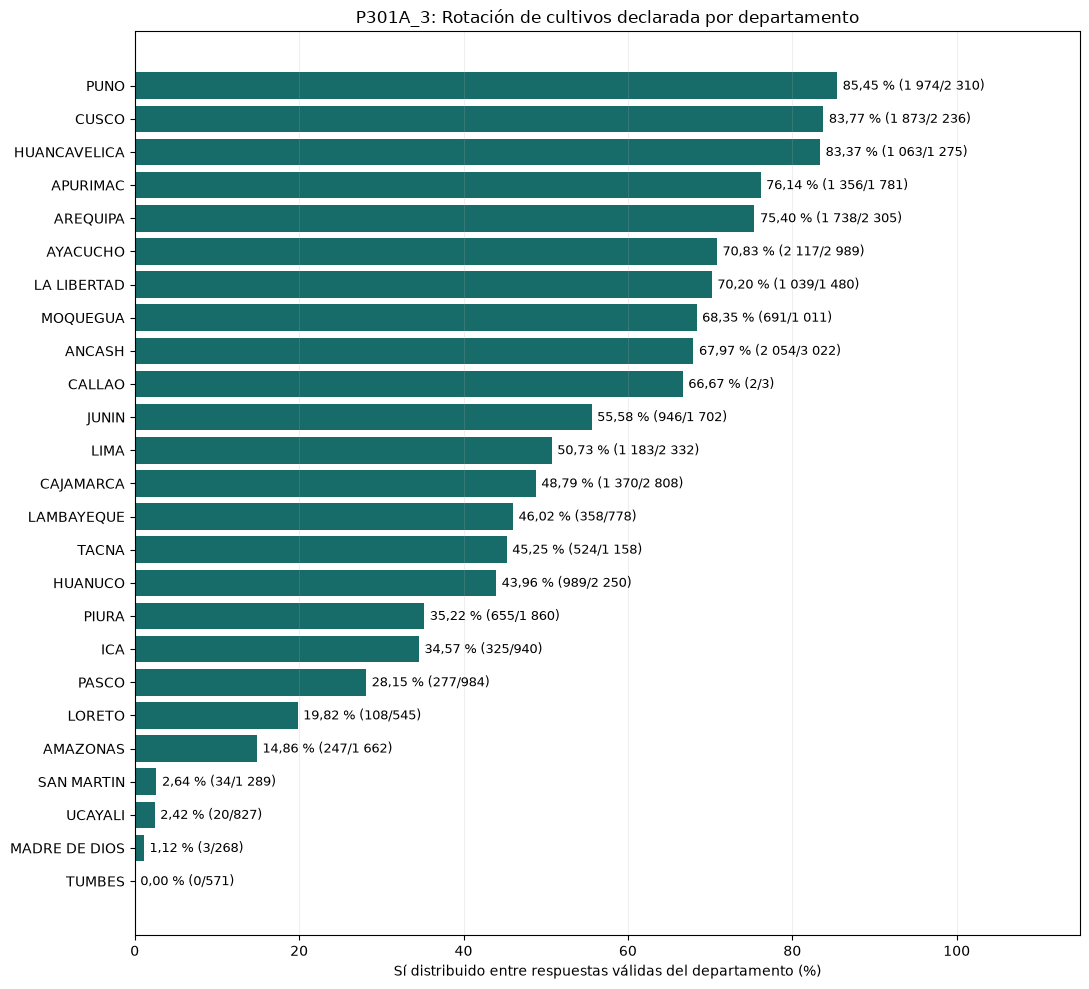

In [29]:
# Tabla de la sección 7.3.
plt.figure(figsize=(11, 10))
barras = plt.barh(tabla_rotacion_departamento.index, tabla_rotacion_departamento["Porcentaje Sí"], color="#176B68")
plt.gca().invert_yaxis()
plt.title("P301A_3: Rotación de cultivos declarada por departamento")
plt.xlabel("Sí distribuido entre respuestas válidas del departamento (%)")
plt.xlim(0, 115)
plt.xticks([0, 20, 40, 60, 80, 100])
plt.bar_label(barras, labels=[f"{p:.2f} % ({si:,}/{n:,})".replace(",", " ").replace(".", ",") for p, si, n in zip(
    tabla_rotacion_departamento["Porcentaje Sí"], tabla_rotacion_departamento["Sí"],
    tabla_rotacion_departamento["Total válido"])], padding=4, fontsize=9)
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

Puno registró 1.974 respuestas afirmativas entre 2.310 válidas (85,45 %); Cusco, 1.873 de 2.236 (83,77 %). Tumbes registró 0 de 571. Callao sólo tiene tres respuestas válidas (dos afirmativas); su posición en el orden no debe interpretarse como una comparación estable.

Se comparan respuestas de las UA conservadas y muestra sus bases; no permite atribuir las diferencias al territorio ni generalizarlas a toda la población. 

### 7.4. Años que llevan practicando rotación

**Pregunta:** ¿Cuántos años llevan realizando la práctica quienes respondieron «Sí» en `P301A_3`?

El diccionario define `P302A_3` como años que llevan realizando la práctica. El resumen conserva los valores registrados y el código posterior identifica ceros, negativos y valores no enteros.


In [30]:
# Años reportados por quienes realizan rotación
anios_originales = df_analisis.loc[df_analisis["P301A_3"] == 1, "P302A_3"]
anios_rotacion = pd.to_numeric(anios_originales, errors="coerce")

print("Registros analizados:", len(anios_originales))
print("Años numéricos:", anios_rotacion.notna().sum())
print("Valores faltantes:", anios_originales.isna().sum())
print("Valores no numéricos:", (anios_originales.notna() & anios_rotacion.isna()).sum())

Registros analizados: 20946
Años numéricos: 20946
Valores faltantes: 0
Valores no numéricos: 0


In [31]:
# Resumen estadístico de los años
print(anios_rotacion.describe())

# Revisar valores particulares
print("\nValores iguales a cero:", (anios_rotacion == 0).sum())
print("Valores negativos:", (anios_rotacion < 0).sum())
print("Valores no enteros:", (anios_rotacion.notna() & (anios_rotacion % 1 != 0)).sum())

count    20946.000000
mean        27.306359
std         14.496148
min          0.000000
25%         15.000000
50%         27.000000
75%         40.000000
max         75.000000
Name: P302A_3, dtype: float64

Valores iguales a cero: 11
Valores negativos: 0
Valores no enteros: 0


In [32]:
# Frecuencia de cada cantidad de años registrada
frecuencia_anios = anios_rotacion.value_counts(dropna=False).sort_index()

Entre las UA que declararon rotar cultivos, existen 20 946 registros y 20 946 valores numéricos, coinciden! La mediana registrada fue 27,00 años. Estos valores indican antigüedad declarada de la práctica, mas no la duración entre dos rotaciones.

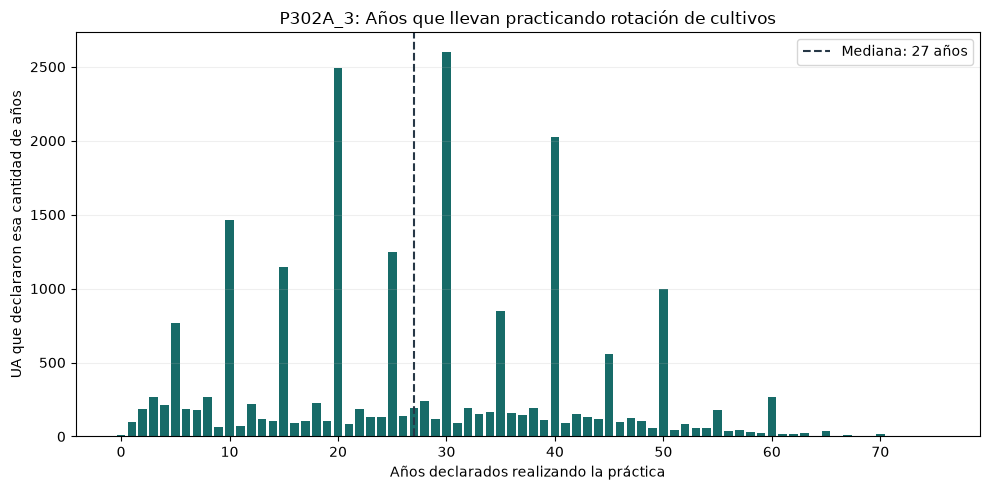

In [33]:
# La distribución conserva todos los años registrados, w los once ceros.
plt.figure(figsize=(10, 5))
plt.bar(frecuencia_anios.index, frecuencia_anios.values, color="#176B68")
plt.axvline(anios_rotacion.median(), color="#263746", linestyle="--", label=f"Mediana: {anios_rotacion.median():.0f} años")
plt.title("P302A_3: Años que llevan practicando rotación de cultivos")
plt.xlabel("Años declarados realizando la práctica")
plt.ylabel("UA que declararon esa cantidad de años")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

#### 7.4.1. Antigüedad frente a la mediana regional

**Pregunta:** ¿Cómo se sitúan los años declarados por cada UA respecto a la mediana de su región natural?

Considerando UA con `P301A_3 = 1`, años numéricos en `P302A_3` y `REGION` reconocida. Se conservan los ceros. `transform("median")` devuelve a cada fila la mediana de su región, mantiene una fila por UA y permite calcular su distancia en años respecto de esa referencia. El resumen original de años permanece igual.


In [34]:
anios_referencia = df_analisis.loc[
    df_analisis["P301A_3"].eq(1) & df_analisis["REGION"].isin([1, 2, 3]),
    ["REGION", "P302A_3"]
].copy()
anios_referencia["Años"] = pd.to_numeric(anios_referencia["P302A_3"], errors="coerce")
anios_referencia = anios_referencia.dropna(subset=["Años"])
anios_referencia["Mediana regional"] = anios_referencia.groupby("REGION")["Años"].transform("median")
anios_referencia["Distancia absoluta"] = (anios_referencia["Años"] - anios_referencia["Mediana regional"]).abs()
anios_referencia["Supera mediana"] = anios_referencia["Años"].gt(anios_referencia["Mediana regional"])
tabla_anios_referencia = anios_referencia.groupby("REGION").agg(
    validas=("Años", "size"), mediana=("Mediana regional", "first"),
    distancia_media=("Distancia absoluta", "mean"), superan=("Supera mediana", "sum")
)
tabla_anios_referencia["Superan (%)"] = (100 * tabla_anios_referencia["superan"] / tabla_anios_referencia["validas"]).round(2)
tabla_anios_referencia = tabla_anios_referencia.rename(index={1: "Costa", 2: "Sierra", 3: "Selva"}, columns={
    "validas": "UA válidas", "mediana": "Mediana regional (años)",
    "distancia_media": "Distancia media absoluta (años)", "superan": "UA que superan mediana"
}).rename_axis("Región natural")
display(tabla_anios_referencia.round(2))

,UA válidas,Mediana regional (años),Distancia media absoluta (años),UA que superan mediana,Superan (%)
Región natural,,,,,
Costa,3649,20.0,10.68,1400,38.37
Sierra,16571,30.0,11.58,6698,40.42
Selva,726,18.0,11.54,355,48.90


La mediana regional fue de 20 años en Costa, 30 en Sierra y 18 en Selva. La distancia media absoluta respecto de esas referencias fue de 10,68, 11,58 y 11,54 años, respectivamente.

Una distancia grande indica mayor separación respecto de la referencia, no una práctica mejor o peor. Quienes superan la mediana no tienen por qué representar exactamente el 50 %: varias UA pueden declarar el mismo número de años.

### 7.5. P301A_1: Análisis de suelos por región natural

**Pregunta:** ¿Cómo varía el análisis de suelos declarado entre Costa, Sierra y Selva?

`P301A_1` corresponde al análisis de suelos y nos permite describir una práctica de diagnóstico del suelo; el perfil 7.1 solo muestra su frecuencia conjunta. El numerador es `Sí` y el denominador las respuestas válidas de cada región.

In [35]:
base_suelos = df_analisis.loc[df_analisis["REGION"].isin([1, 2, 3])]
tabla_suelos_region = pd.crosstab(base_suelos["REGION"], base_suelos["P301A_1"]).reindex(
    index=[1, 2, 3], columns=[1, 2], fill_value=0).rename(columns={1: "Sí", 2: "No"})
tabla_suelos_region["UA elegibles"] = base_suelos.groupby("REGION").size().reindex([1, 2, 3], fill_value=0)
tabla_suelos_region["Total válido"] = tabla_suelos_region["Sí"] + tabla_suelos_region["No"]
tabla_suelos_region["Nulos"] = base_suelos["P301A_1"].isna().groupby(base_suelos["REGION"]).sum()
tabla_suelos_region["Otros códigos"] = tabla_suelos_region["UA elegibles"] - tabla_suelos_region["Total válido"] - tabla_suelos_region["Nulos"]
tabla_suelos_region["Sí (%)"] = (100 * tabla_suelos_region["Sí"] / tabla_suelos_region["Total válido"].replace(0, float("nan"))).round(2)
tabla_suelos_region = tabla_suelos_region.rename(index={1: "Costa", 2: "Sierra", 3: "Selva"}).rename_axis(index="Región natural", columns=None)
print("UA sin región reconocida:", len(df_analisis) - len(base_suelos))
display(tabla_suelos_region)

UA sin región reconocida: 0


,Sí,No,UA elegibles,Total válido,Nulos,Otros códigos,Sí (%)
Región natural,,,,,,,
Costa,499,8254,8753,8753,0,0,5.70
Sierra,395,22026,22421,22421,0,0,1.76
Selva,349,6863,7212,7212,0,0,4.84


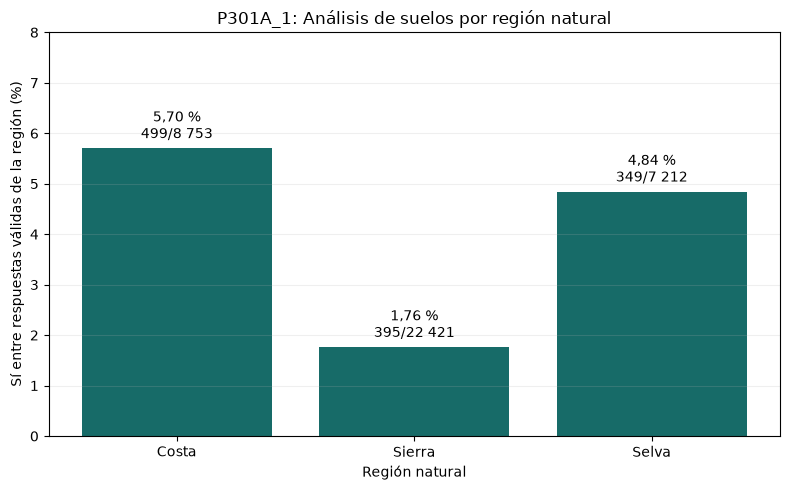

In [36]:
plt.figure(figsize=(8, 5))
barras = plt.bar(tabla_suelos_region.index, tabla_suelos_region["Sí (%)"], color="#176B68")
plt.title("P301A_1: Análisis de suelos por región natural")
plt.xlabel("Región natural")
plt.ylabel("Sí entre respuestas válidas de la región (%)")
plt.ylim(0, 8)
plt.bar_label(barras, labels=[f"{p:.2f} %\n{si:,}/{n:,}".replace(",", " ").replace(".", ",") for p, si, n in zip(
    tabla_suelos_region["Sí (%)"], tabla_suelos_region["Sí"], tabla_suelos_region["Total válido"])], padding=4)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

Costa registró 499 de 8.753 respuestas afirmativas (5,70 %), frente a 349 de 7.212 en Selva (4,84 %) y 395 de 22.421 en Sierra (1,76 %). La respuesta no informa sobre la fecha, la calidad ni el uso de los resultados del análisis.

### 7.6. P301A_2: Mezclar la tierra con materia orgánica por región natural

**Pregunta:** ¿Cómo cambia por región natural la mezcla de tierra con materia orgánica declarada?

Mezclar la tierra con materia orgánica. Estudia la incorporación de rastrojos, estiércol, compost, humus u otra materia orgánica al suelo. Es distinta de realizar un análisis de suelos.

In [37]:
base_materia = df_analisis.loc[df_analisis["REGION"].isin([1, 2, 3])]
tabla_materia_region = pd.crosstab(base_materia["REGION"], base_materia["P301A_2"]).reindex(
    index=[1, 2, 3], columns=[1, 2], fill_value=0).rename(columns={1: "Sí", 2: "No"})
tabla_materia_region["UA elegibles"] = base_materia.groupby("REGION").size().reindex([1, 2, 3], fill_value=0)
tabla_materia_region["Total válido"] = tabla_materia_region["Sí"] + tabla_materia_region["No"]
tabla_materia_region["Nulos"] = base_materia["P301A_2"].isna().groupby(base_materia["REGION"]).sum()
tabla_materia_region["Otros códigos"] = tabla_materia_region["UA elegibles"] - tabla_materia_region["Total válido"] - tabla_materia_region["Nulos"]
tabla_materia_region["Sí (%)"] = (100 * tabla_materia_region["Sí"] / tabla_materia_region["Total válido"].replace(0, float("nan"))).round(2)
tabla_materia_region = tabla_materia_region.rename(index={1: "Costa", 2: "Sierra", 3: "Selva"}).rename_axis(index="Región natural", columns=None)
print("UA sin región reconocida:", len(df_analisis) - len(base_materia))
display(tabla_materia_region)

UA sin región reconocida: 0


,Sí,No,UA elegibles,Total válido,Nulos,Otros códigos,Sí (%)
Región natural,,,,,,,
Costa,4835,3918,8753,8753,0,0,55.24
Sierra,17021,5400,22421,22421,0,0,75.92
Selva,1451,5761,7212,7212,0,0,20.12


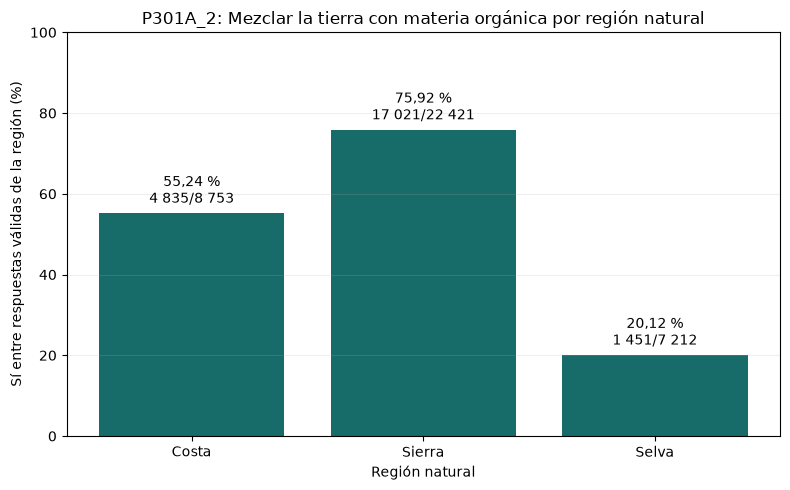

In [38]:
plt.figure(figsize=(8, 5))
barras = plt.bar(tabla_materia_region.index, tabla_materia_region["Sí (%)"], color="#176B68")
plt.title("P301A_2: Mezclar la tierra con materia orgánica por región natural")
plt.xlabel("Región natural")
plt.ylabel("Sí entre respuestas válidas de la región (%)")
plt.ylim(0, 100)
plt.bar_label(barras, labels=[f"{p:.2f} %\n{si:,}/{n:,}".replace(",", " ").replace(".", ",") for p, si, n in zip(
    tabla_materia_region["Sí (%)"], tabla_materia_region["Sí"], tabla_materia_region["Total válido"])], padding=4)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

Declararon la práctica 17.021 de 22.421 UA en Sierra (75,92 %), 4.835 de 8.753 en Costa (55,24 %) y 1.451 de 7.212 en Selva (20,12 %). No se registra aquí la cantidad incorporada ni un efecto medido sobre el suelo.

### 7.7. P301A_12A: Análisis de agua por región natural

**Pregunta:** ¿Qué proporción de UA declaró realizar análisis de agua en cada región natural?

Describe una práctica de diagnóstico del agua, distinta de determinar cuánto o cuándo regar y del análisis de suelos.

In [39]:
base_agua = df_analisis.loc[df_analisis["REGION"].isin([1, 2, 3])]
tabla_agua_region = pd.crosstab(base_agua["REGION"], base_agua["P301A_12A"]).reindex(
    index=[1, 2, 3], columns=[1, 2], fill_value=0).rename(columns={1: "Sí", 2: "No"})
tabla_agua_region["UA elegibles"] = base_agua.groupby("REGION").size().reindex([1, 2, 3], fill_value=0)
tabla_agua_region["Total válido"] = tabla_agua_region["Sí"] + tabla_agua_region["No"]
tabla_agua_region["Nulos"] = base_agua["P301A_12A"].isna().groupby(base_agua["REGION"]).sum()
tabla_agua_region["Otros códigos"] = tabla_agua_region["UA elegibles"] - tabla_agua_region["Total válido"] - tabla_agua_region["Nulos"]
tabla_agua_region["Sí (%)"] = (100 * tabla_agua_region["Sí"] / tabla_agua_region["Total válido"].replace(0, float("nan"))).round(2)
tabla_agua_region = tabla_agua_region.rename(index={1: "Costa", 2: "Sierra", 3: "Selva"}).rename_axis(index="Región natural", columns=None)
print("UA sin región reconocida:", len(df_analisis) - len(base_agua))
display(tabla_agua_region)

UA sin región reconocida: 0


,Sí,No,UA elegibles,Total válido,Nulos,Otros códigos,Sí (%)
Región natural,,,,,,,
Costa,218,8535,8753,8753,0,0,2.49
Sierra,100,22321,22421,22421,0,0,0.45
Selva,15,7197,7212,7212,0,0,0.21


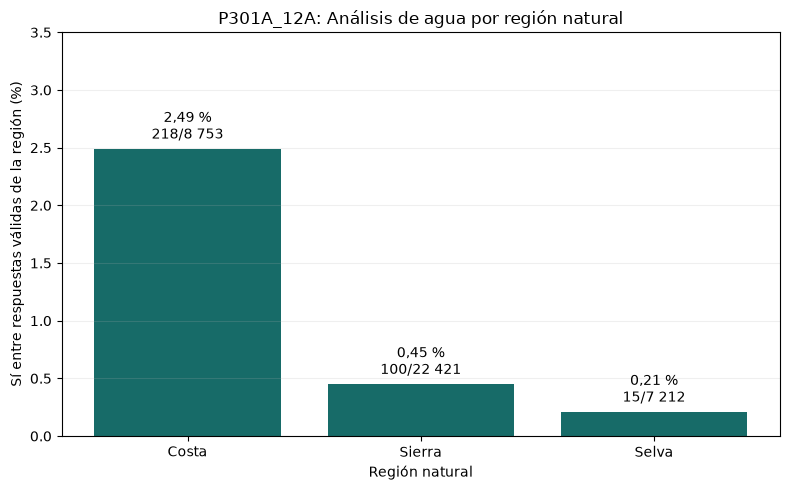

In [40]:
plt.figure(figsize=(8, 5))
barras = plt.bar(tabla_agua_region.index, tabla_agua_region["Sí (%)"], color="#176B68")
plt.title("P301A_12A: Análisis de agua por región natural")
plt.xlabel("Región natural")
plt.ylabel("Sí entre respuestas válidas de la región (%)")
plt.ylim(0, 3.5)
plt.bar_label(barras, labels=[f"{p:.2f} %\n{si:,}/{n:,}".replace(",", " ").replace(".", ",") for p, si, n in zip(
    tabla_agua_region["Sí (%)"], tabla_agua_region["Sí"], tabla_agua_region["Total válido"])], padding=4)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

Costa registró 218 de 8.753 respuestas afirmativas (2,49 %); Sierra, 100 de 22.421 (0,45 %), y Selva, 15 de 7.212 (0,21 %). Los quince afirmativos de Selva requieren una lectura prudente. La pregunta no mide la calidad del agua ni demuestra contaminación.

### 7.8. P301A_14: Usar fertilizantes por región natural

**Pregunta:** ¿Cómo varía el uso declarado de fertilizantes entre las tres regiones naturales?

In [41]:
base_fertilizantes = df_analisis.loc[df_analisis["REGION"].isin([1, 2, 3])]
tabla_fertilizantes_region = pd.crosstab(base_fertilizantes["REGION"], base_fertilizantes["P301A_14"]).reindex(
    index=[1, 2, 3], columns=[1, 2], fill_value=0).rename(columns={1: "Sí", 2: "No"})
tabla_fertilizantes_region["UA elegibles"] = base_fertilizantes.groupby("REGION").size().reindex([1, 2, 3], fill_value=0)
tabla_fertilizantes_region["Total válido"] = tabla_fertilizantes_region["Sí"] + tabla_fertilizantes_region["No"]
tabla_fertilizantes_region["Nulos"] = base_fertilizantes["P301A_14"].isna().groupby(base_fertilizantes["REGION"]).sum()
tabla_fertilizantes_region["Otros códigos"] = tabla_fertilizantes_region["UA elegibles"] - tabla_fertilizantes_region["Total válido"] - tabla_fertilizantes_region["Nulos"]
tabla_fertilizantes_region["Sí (%)"] = (100 * tabla_fertilizantes_region["Sí"] / tabla_fertilizantes_region["Total válido"].replace(0, float("nan"))).round(2)
tabla_fertilizantes_region = tabla_fertilizantes_region.rename(index={1: "Costa", 2: "Sierra", 3: "Selva"}).rename_axis(index="Región natural", columns=None)
print("UA sin región reconocida:", len(df_analisis) - len(base_fertilizantes))
display(tabla_fertilizantes_region)

UA sin región reconocida: 0


,Sí,No,UA elegibles,Total válido,Nulos,Otros códigos,Sí (%)
Región natural,,,,,,,
Costa,7235,1518,8753,8753,0,0,82.66
Sierra,11596,10825,22421,22421,0,0,51.72
Selva,3273,3939,7212,7212,0,0,45.38


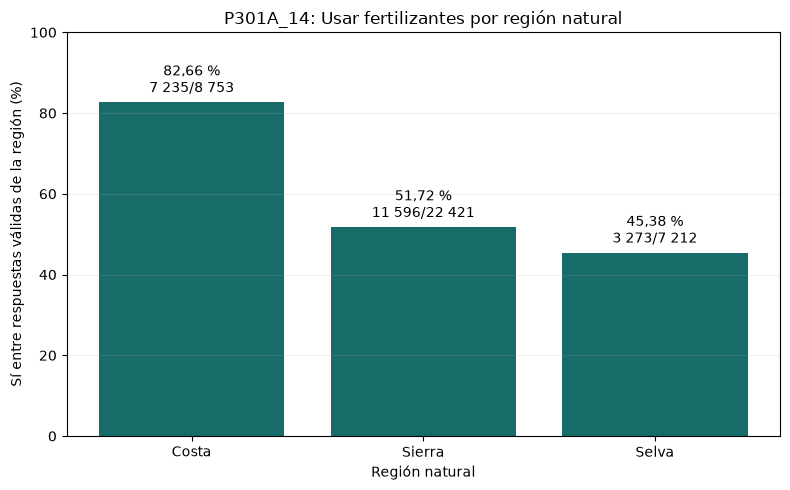

In [42]:
plt.figure(figsize=(8, 5))
barras = plt.bar(tabla_fertilizantes_region.index, tabla_fertilizantes_region["Sí (%)"], color="#176B68")
plt.title("P301A_14: Usar fertilizantes por región natural")
plt.xlabel("Región natural")
plt.ylabel("Sí entre respuestas válidas de la región (%)")
plt.ylim(0, 100)
plt.bar_label(barras, labels=[f"{p:.2f} %\n{si:,}/{n:,}".replace(",", " ").replace(".", ",") for p, si, n in zip(
    tabla_fertilizantes_region["Sí (%)"], tabla_fertilizantes_region["Sí"], tabla_fertilizantes_region["Total válido"])], padding=4)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

Declararon usar fertilizantes 7.235 de 8.753 UA en Costa (82,66 %), 11.596 de 22.421 en Sierra (51,72 %) y 3.273 de 7.212 en Selva (45,38 %). La respuesta no distingue dosis, composición, necesidad agronómica ni uso adecuado.

### 7.9. P301A_15: Usar plaguicidas por región natural

**Pregunta:** ¿Cómo varía por región natural el uso declarado de plaguicidas?

Describe el uso de insecticidas, fungicidas, herbicidas y los demás productos incluidos en la pregunta oficial. Es diferente del uso de fertilizantes.

In [43]:
base_plaguicidas = df_analisis.loc[df_analisis["REGION"].isin([1, 2, 3])]
tabla_plaguicidas_region = pd.crosstab(base_plaguicidas["REGION"], base_plaguicidas["P301A_15"]).reindex(
    index=[1, 2, 3], columns=[1, 2], fill_value=0).rename(columns={1: "Sí", 2: "No"})
tabla_plaguicidas_region["UA elegibles"] = base_plaguicidas.groupby("REGION").size().reindex([1, 2, 3], fill_value=0)
tabla_plaguicidas_region["Total válido"] = tabla_plaguicidas_region["Sí"] + tabla_plaguicidas_region["No"]
tabla_plaguicidas_region["Nulos"] = base_plaguicidas["P301A_15"].isna().groupby(base_plaguicidas["REGION"]).sum()
tabla_plaguicidas_region["Otros códigos"] = tabla_plaguicidas_region["UA elegibles"] - tabla_plaguicidas_region["Total válido"] - tabla_plaguicidas_region["Nulos"]
tabla_plaguicidas_region["Sí (%)"] = (100 * tabla_plaguicidas_region["Sí"] / tabla_plaguicidas_region["Total válido"].replace(0, float("nan"))).round(2)
tabla_plaguicidas_region = tabla_plaguicidas_region.rename(index={1: "Costa", 2: "Sierra", 3: "Selva"}).rename_axis(index="Región natural", columns=None)
print("UA sin región reconocida:", len(df_analisis) - len(base_plaguicidas))
display(tabla_plaguicidas_region)

UA sin región reconocida: 0


,Sí,No,UA elegibles,Total válido,Nulos,Otros códigos,Sí (%)
Región natural,,,,,,,
Costa,7332,1421,8753,8753,0,0,83.77
Sierra,13094,9327,22421,22421,0,0,58.40
Selva,3827,3385,7212,7212,0,0,53.06


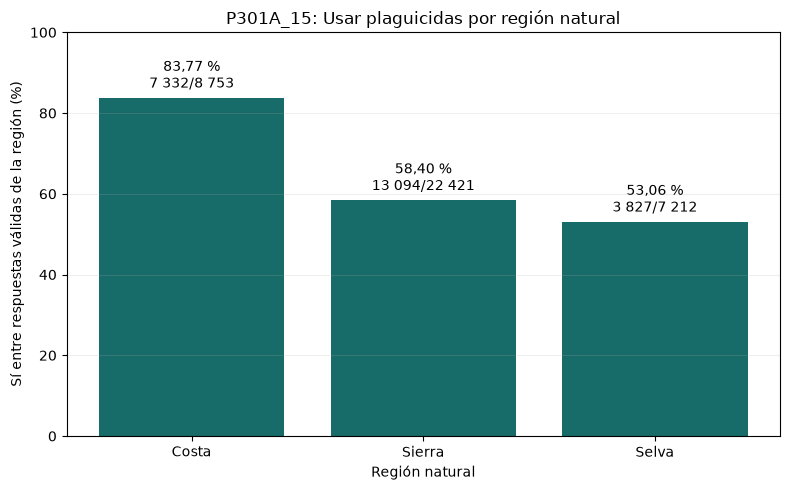

In [44]:
plt.figure(figsize=(8, 5))
barras = plt.bar(tabla_plaguicidas_region.index, tabla_plaguicidas_region["Sí (%)"], color="#176B68")
plt.title("P301A_15: Usar plaguicidas por región natural")
plt.xlabel("Región natural")
plt.ylabel("Sí entre respuestas válidas de la región (%)")
plt.ylim(0, 100)
plt.bar_label(barras, labels=[f"{p:.2f} %\n{si:,}/{n:,}".replace(",", " ").replace(".", ",") for p, si, n in zip(
    tabla_plaguicidas_region["Sí (%)"], tabla_plaguicidas_region["Sí"], tabla_plaguicidas_region["Total válido"])], padding=4)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

**Interpretación:** Costa registró 7.332 de 8.753 respuestas afirmativas (83,77 %); Sierra, 13.094 de 22.421 (58,40 %), y Selva, 3.827 de 7.212 (53,06 %). Declarar uso no demuestra abuso, exposición peligrosa ni contaminación; no se informa aquí sobre dosis o aplicación.

## 8. Visualizaciones e interpretación

### 8.1. Rotación de cultivos por región natural

El gráfico compara el porcentaje de respuestas `Sí` a `P301A_3` en Costa, Sierra y Selva. La tabla de la sección 7.2 permite consultar los numeradores y denominadores.


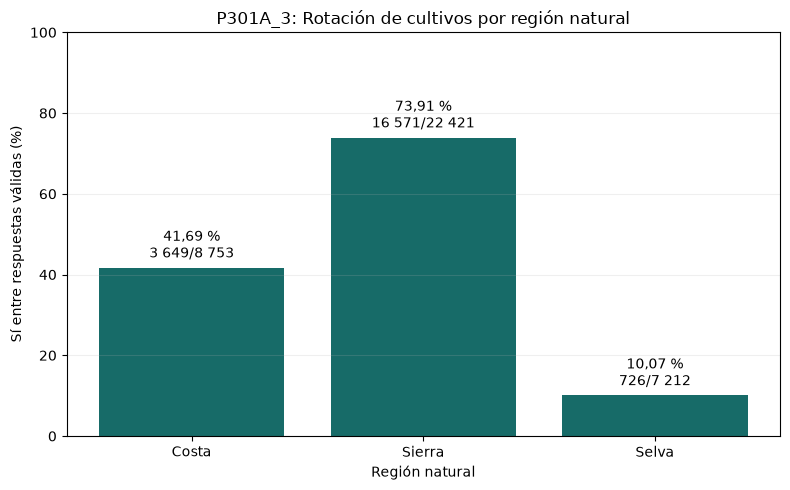

In [45]:
plt.figure(figsize=(8, 5))
barras = plt.bar(tabla_rotacion_region.index, tabla_rotacion_region["Porcentaje Sí"], color="#176B68")
plt.title("P301A_3: Rotación de cultivos por región natural")
plt.xlabel("Región natural")
plt.ylabel("Sí entre respuestas válidas (%)")
plt.ylim(0, 100)
plt.bar_label(barras, labels=[
    f"{p:.2f} %\n{si:,}/{total:,}".replace(",", " ").replace(".", ",")
    for p,si,total in zip(tabla_rotacion_region["Porcentaje Sí"],
                          tabla_rotacion_region["Sí"], tabla_rotacion_region["Total válido"])
], padding=4)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

Sierra registró el mayor porcentaje de UA que declararon rotar cultivos: 16.571 de 22.421 (73,91 %). Le siguieron Costa, con 3.649 de 8.753 (41,69 %), y Selva, con 726 de 7.212 (10,07 %). Estas diferencias describen respuestas de la base analizada, no permiten explicar por sí solas sus causas.


### 8.2. Comparación de prácticas agrícolas

Se comparan ocho prácticas con cobertura en las tres regiones. `P301A_12B` se excluye de este gráfico porque únicamente corresponde a Sierra.


In [46]:
# Seleccionar las prácticas con cobertura territorial general
practicas_grafico = resumen_practicas[resumen_practicas["codigo"]!="P301A_12B"].copy()
print("Prácticas seleccionadas:", len(practicas_grafico))

Prácticas seleccionadas: 8


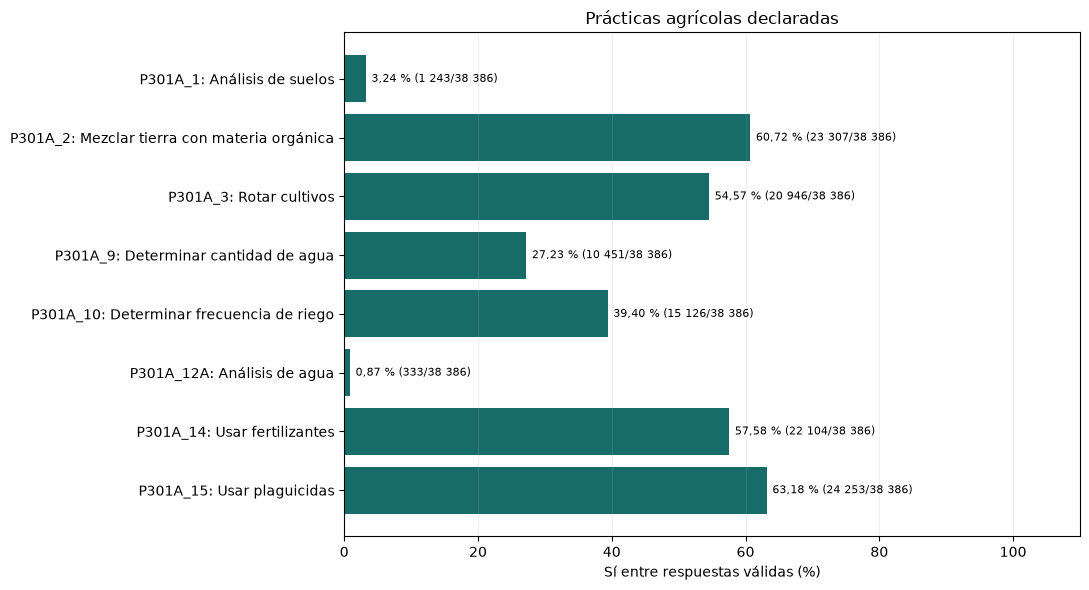

In [47]:
etiquetas_practicas = {
    "P301A_1": "P301A_1: Análisis de suelos",
    "P301A_2": "P301A_2: Mezclar tierra con materia orgánica",
    "P301A_3": "P301A_3: Rotar cultivos",
    "P301A_9": "P301A_9: Determinar cantidad de agua",
    "P301A_10": "P301A_10: Determinar frecuencia de riego",
    "P301A_12A": "P301A_12A: Análisis de agua",
    "P301A_14": "P301A_14: Usar fertilizantes",
    "P301A_15": "P301A_15: Usar plaguicidas",
}
plt.figure(figsize=(11, 6))
barras = plt.barh(
    practicas_grafico["codigo"].map(etiquetas_practicas),
    practicas_grafico["porcentaje_si"], color="#176B68"
)
plt.gca().invert_yaxis()
plt.title("Prácticas agrícolas declaradas")
plt.xlabel("Sí entre respuestas válidas (%)")
plt.xlim(0, 110)
plt.bar_label(barras, labels=[
    f"{p:.2f} % ({si:,}/{total:,})".replace(",", " ").replace(".", ",")
    for p,si,total in zip(practicas_grafico["porcentaje_si"],
                          practicas_grafico["si"], practicas_grafico["validas_1_2"])
], padding=4, fontsize=8)
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

Entre las ocho prácticas comparables, el uso de plaguicidas tuvo el mayor porcentaje declarado (24.253 de 38.386 UA; 63,18 %), seguido de mezclar tierra con materia orgánica (23.307; 60,72 %).

El análisis de agua fue el menos mencionado (333; 0,87 %). Cada práctica se calcula por separado; una misma UA puede declarar varias.

# 1 Laboratorio 02

## 11. UA vinculadas a cultivos seleccionados

En el módulo 03 identificamos cultivos y periodos de cosecha. En el módulo 08 se aportan las prácticas declaradas por las UA.

### 11.1. Diccionario y unidad de análisis

El diccionario define `P204_NOM` como los cultivos cosechados en cada parcela durante los últimos doce meses.

`P206` indica el inicio de cosecha y `P207` su final real o previsto. Sus filas son registros de cosecha; cabe aclarar que una UA puede tener varias parcelas, cultivos y cosechas.

La llave utilizada es `ANIO`, `CCDD`, `CCPP`, `CCDI`, `NSEGM`, `ID_PROD`, `UA`. Los diccionarios de ambos módulos describen estos identificadores de la misma forma. La unión de control valida la cardinalidad con `merge(validate="one_to_one")`. Se usa el mismo campo `NSEGM` de ambos archivos; no se lo reemplaza por `CLUSTER` y tampoco se utiliza Carátula.

In [48]:
llave_aux = ["ANIO", "CCDD", "CCPP", "CCDI", "NSEGM", "ID_PROD", "UA"]
fechas_aux = ["P206_INI_MES", "P206_INI_ANIO", "P207_FIN_MES", "P207_FIN_ANIO"]
departamentos_aux = [15, 11, 4, 12, 22]
cultivos_aux = pd.read_parquet("../data/raw/03_CAP200AB.parquet")
diccionario_aux = pd.read_excel("../data/raw/DICC_ENA_2025.xlsx", sheet_name="03_CAP200AB")

display(diccionario_aux.loc[
    diccionario_aux["NOMBRE DE LA VARIABLE"].isin(["P204_NOM"] + fechas_aux),
    ["NOMBRE DE LA VARIABLE", "DESCRIPCIÓN DE LAS VARIABLES"]
].reset_index(drop=True))

# Filtrar y delimitar a nuestros cinco departamentos.
cultivos_aux = cultivos_aux.loc[
    cultivos_aux["NOMBREDD"].notna() & cultivos_aux["CCDD"].isin(departamentos_aux)
].copy()

print("Registros de cosecha en los cinco departamentos:", len(cultivos_aux))

,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES
0,P204_NOM,"EN ESTA PARCELA, EN LOS ÚLTIMOS 12 MESES, DE……..."
1,P206_INI_MES,¿CUÁNDO FUE LA FECHA DE INICIO DE COSECHA DE…....
2,P206_INI_ANIO,¿CUÁNDO FUE LA FECHA DE INICIO DE COSECHA DE…....
3,P207_FIN_MES,¿CUÁNDO FUE O SERÁ LA FECHA FINAL DE COSECHA D...
4,P207_FIN_ANIO,¿CUÁNDO FUE O SERÁ LA FECHA FINAL DE COSECHA D...


Registros de cosecha en los cinco departamentos: 31480


### 11.2. Selección y codificación

Se agrupan los nombres que contienen frijol, maíz o haba. Los demás se seleccionan por el nombre solicitado. Para café se utiliza el nombre observado `CAFE PERGAMINO`; limón agrupa `LIMON ACIDO`, `LIMON DULCE` y `LIMON RUGOSO`. Se conserva `P204_NOM` y el código oficial `P204_COD`; `cultivo_grupo` es una agrupación analítica, no un nuevo código oficial.

El filtro literal solicitado incluye `MAIZ CHALA`. Se mantiene visible y separado en el control, sin afirmar que su destino sea consumo humano. Su inclusión requiere aclaración del profesor; retirarlo sin esa aclaración cambiaría la regla de selección y las bases.


In [49]:
grupos_aux = ["FRIJOL", "MAIZ", "HABA", "ARROZ CASCARA", "PALTO",
              "PAPA AMARGA", "PAPA AMARILLA", "PAPA BLANCA", "PAPA COLOR",
              "PAPA HUAYRO", "PAPA NATIVA", "CAMOTE", "MANGO", "MANDARINA",
              "CACAO", "TRIGO", "CAFE", "LIMON", "NARANJO", "YUCA", "PLATANO", "MANZANO"]
nombre_aux = (cultivos_aux["P204_NOM"].str.normalize("NFKD")
              .str.encode("ascii", errors="ignore").str.decode("ascii").str.upper().str.strip())
cultivos_aux["cultivo_grupo"] = nombre_aux.replace({
    "CAFE PERGAMINO": "CAFE", "LIMON ACIDO": "LIMON",
    "LIMON DULCE": "LIMON", "LIMON RUGOSO": "LIMON"
})
for grupo in ["FRIJOL", "MAIZ", "HABA"]:
    cultivos_aux.loc[nombre_aux.str.contains(grupo, na=False), "cultivo_grupo"] = grupo
cultivos_aux = cultivos_aux.loc[cultivos_aux["cultivo_grupo"].isin(grupos_aux)].copy()

print("Registros seleccionados:", len(cultivos_aux))
print("UA distintas:", len(cultivos_aux[llave_aux].drop_duplicates()))
print("Grupos observados:", cultivos_aux["cultivo_grupo"].nunique())
print("Registros de MAIZ CHALA incluidos:", cultivos_aux["P204_NOM"].eq("MAIZ CHALA").sum())
display(cultivos_aux.loc[
    nombre_aux.reindex(cultivos_aux.index).str.contains("CAFE|LIMON|CHALA", na=False),
    ["P204_NOM", "P204_COD", "cultivo_grupo"]
].drop_duplicates().sort_values("cultivo_grupo").reset_index(drop=True))

Registros seleccionados: 15373
UA distintas: 5898
Grupos observados: 22
Registros de MAIZ CHALA incluidos: 755


,P204_NOM,P204_COD,cultivo_grupo
0,CAFE PERGAMINO,1203,CAFE
1,LIMON ACIDO,1140,LIMON
2,LIMON RUGOSO,1142,LIMON
3,LIMON DULCE,1141,LIMON
4,MAIZ CHALA,2706,MAIZ


### 11.3. Periodo registrado y categorías

Se cuentan los meses calendario incluyendo inicio y final: `12 × (año final − año inicial) + mes final − mes inicial + 1`.

Una cosecha que empieza y termina en el mismo mes ocupa un mes en este conteo. No representa meses transcurridos exactos ni tiempo desde siembra hasta madurez.

- Muy corto: 1–3 
- Corto: 4–6 
- Mediano: 7–9 
- Largo: 10–12 
- Muy largo: Más de 12 

Los casos inválidos se muestran y no reciben categoría; no se sustituyen por cero.

In [50]:
fechas_num_aux = cultivos_aux[fechas_aux].apply(pd.to_numeric, errors="coerce")
fechas_validas_aux = (
    fechas_num_aux.notna().all(axis=1)
    & fechas_num_aux.mod(1).eq(0).all(axis=1)
    & fechas_num_aux["P206_INI_MES"].between(1, 12)
    & fechas_num_aux["P207_FIN_MES"].between(1, 12)
    & fechas_num_aux[["P206_INI_ANIO", "P207_FIN_ANIO"]].ge(1).all(axis=1)
)
meses_aux = ((fechas_num_aux["P207_FIN_ANIO"] - fechas_num_aux["P206_INI_ANIO"]) * 12
             + fechas_num_aux["P207_FIN_MES"] - fechas_num_aux["P206_INI_MES"] + 1)
cultivos_aux["meses_cosecha"] = meses_aux.where(fechas_validas_aux & meses_aux.ge(1))
categorias_aux = ["Muy corto", "Corto", "Mediano", "Largo", "Muy largo"]
cultivos_aux["categoria_cosecha"] = pd.cut(
    cultivos_aux["meses_cosecha"], bins=[0, 3, 6, 9, 12, float("inf")], labels=categorias_aux
)
control_periodos_aux = cultivos_aux["categoria_cosecha"].value_counts(sort=False).to_frame("Registros de cosecha")
print("Fechas sin periodo válido:", cultivos_aux["meses_cosecha"].isna().sum())
print("Inicio y final en el mismo mes:", meses_aux.eq(1).sum())
print("Años registrados:", sorted(pd.unique(fechas_num_aux[["P206_INI_ANIO", "P207_FIN_ANIO"]].values.ravel())))
display(control_periodos_aux)

Fechas sin periodo válido: 0
Inicio y final en el mismo mes: 8474
Años registrados: [np.int64(2024), np.int64(2025)]


,Registros de cosecha
categoria_cosecha,
Muy corto,11298
Corto,1232
Mediano,29
Largo,2814
Muy largo,0


### 11.4. Correspondencias

Relacionamos las unidades agropecuarias del módulo 03 con las del módulo 08 mediante sus identificadores.

De las 5.898 unidades agropecuarias seleccionadas, encontramos 5.897 coincidencias. Tan sólo existe una que no pudo relacionarse.

Para evitar duplicaciones, contamos cada unidad una sola vez dentro de cada grupo de cultivo o categoría de cosecha. Una misma unidad agropecuaria puede registrar varios cultivos, pero sus respuestas sobre buenas prácticas agrícolas corresponden a la unidad en general, no a un cultivo específico.

In [51]:
atributos_aux = ["REGION", "RESFIN", "CODIGO"]
ua_aux = cultivos_aux[llave_aux + atributos_aux].drop_duplicates()
base_modulo_aux = df_analisis.loc[df_analisis["CCDD"].isin(departamentos_aux)].copy()

revision_union_aux = base_modulo_aux[llave_aux + atributos_aux].merge(
    ua_aux, on=llave_aux, how="outer", validate="one_to_one", indicator=True,
    suffixes=("_modulo", "_03")
)
control_union_aux = revision_union_aux["_merge"].value_counts().rename(index={
    "both": "UA coincidentes", "left_only": "UA del módulo sin registro seleccionado enlazado",
    "right_only": "UA seleccionadas del 03 sin correspondencia en el módulo"
}).to_frame("UA")
display(control_union_aux)
display(revision_union_aux.loc[revision_union_aux["_merge"].eq("right_only"), llave_aux])

ua_cultivo_aux = cultivos_aux[llave_aux + ["cultivo_grupo"]].drop_duplicates()
ua_periodo_aux = cultivos_aux.dropna(subset=["categoria_cosecha"])[
    llave_aux + ["categoria_cosecha"]
].drop_duplicates()
# Cada fila de la izquierda conserva una sola respuesta del módulo.
ua_cultivo_aux = ua_cultivo_aux.merge(
    base_modulo_aux[llave_aux + ["P301A_3"]], on=llave_aux, how="inner", validate="many_to_one")
ua_periodo_aux = ua_periodo_aux.merge(
    base_modulo_aux[llave_aux + ["P301A_3"]], on=llave_aux, how="inner", validate="many_to_one")
print("UA distintas enlazadas:", len(ua_cultivo_aux[llave_aux].drop_duplicates()))
print("Pertenencias UA-cultivo:", len(ua_cultivo_aux), "| Pertenencias UA-categoría:", len(ua_periodo_aux))

,UA
_merge,
UA coincidentes,5897
UA del módulo sin registro seleccionado enlazado,2671
UA seleccionadas del 03 sin correspondencia en el módulo,1


,ANIO,CCDD,CCPP,CCDI,NSEGM,ID_PROD,UA
7299,2025,22.0,1.0,1.0,38336,3,3


UA distintas enlazadas: 5897
Pertenencias UA-cultivo: 10967 | Pertenencias UA-categoría: 7621


### 11.5. Rotación por grupo de cultivo

**Pregunta:** ¿Qué proporción declaró rotar los cultivos entre las UA vinculadas a cada grupo seleccionado?

`P301A_3`: realizar la práctica de rotar los cultivos para proteger el suelo. Permite describir la práctica agrícola en grupos de UA con cultivos registrados, en lugar de repetir la distribución de cosechas del módulo 03.

Consideramos que el denominador de cada porcentaje es `Sí + No` del grupo; se muestran los elegibles y las respuestas sin valor válido. Los grupos se superponen, mas no representan una comparación con factores de expansión.

In [52]:
validas_cultivo_aux = ua_cultivo_aux["P301A_3"].isin([1, 2])
tabla_rotacion_cultivo = pd.crosstab(
    ua_cultivo_aux.loc[validas_cultivo_aux, "cultivo_grupo"],
    ua_cultivo_aux.loc[validas_cultivo_aux, "P301A_3"]
).reindex(index=grupos_aux, columns=[1, 2], fill_value=0).rename(columns={1: "Sí", 2: "No"})
tabla_rotacion_cultivo["UA elegibles"] = ua_cultivo_aux.groupby("cultivo_grupo").size().reindex(grupos_aux, fill_value=0)
tabla_rotacion_cultivo["Total válido"] = tabla_rotacion_cultivo["Sí"] + tabla_rotacion_cultivo["No"]
tabla_rotacion_cultivo["Sin respuesta válida"] = tabla_rotacion_cultivo["UA elegibles"] - tabla_rotacion_cultivo["Total válido"]
tabla_rotacion_cultivo["Sí (%)"] = (100 * tabla_rotacion_cultivo["Sí"] / tabla_rotacion_cultivo["Total válido"].replace(0, float("nan"))).round(2)
tabla_rotacion_cultivo = tabla_rotacion_cultivo.sort_values("Sí (%)", ascending=False).rename_axis(index="Grupo de cultivo", columns=None)
display(tabla_rotacion_cultivo)

,Sí,No,UA elegibles,Total válido,Sin respuesta válida,Sí (%)
Grupo de cultivo,,,,,,
TRIGO,103,7,110,110,0,93.64
HABA,337,32,369,369,0,91.33
PAPA BLANCA,973,113,1086,1086,0,89.59
PAPA NATIVA,166,20,186,186,0,89.25
CAMOTE,94,15,109,109,0,86.24
PAPA COLOR,123,20,143,143,0,86.01
PAPA HUAYRO,53,10,63,63,0,84.13
PAPA AMARILLA,63,14,77,77,0,81.82
PAPA AMARGA,15,5,20,20,0,75.00


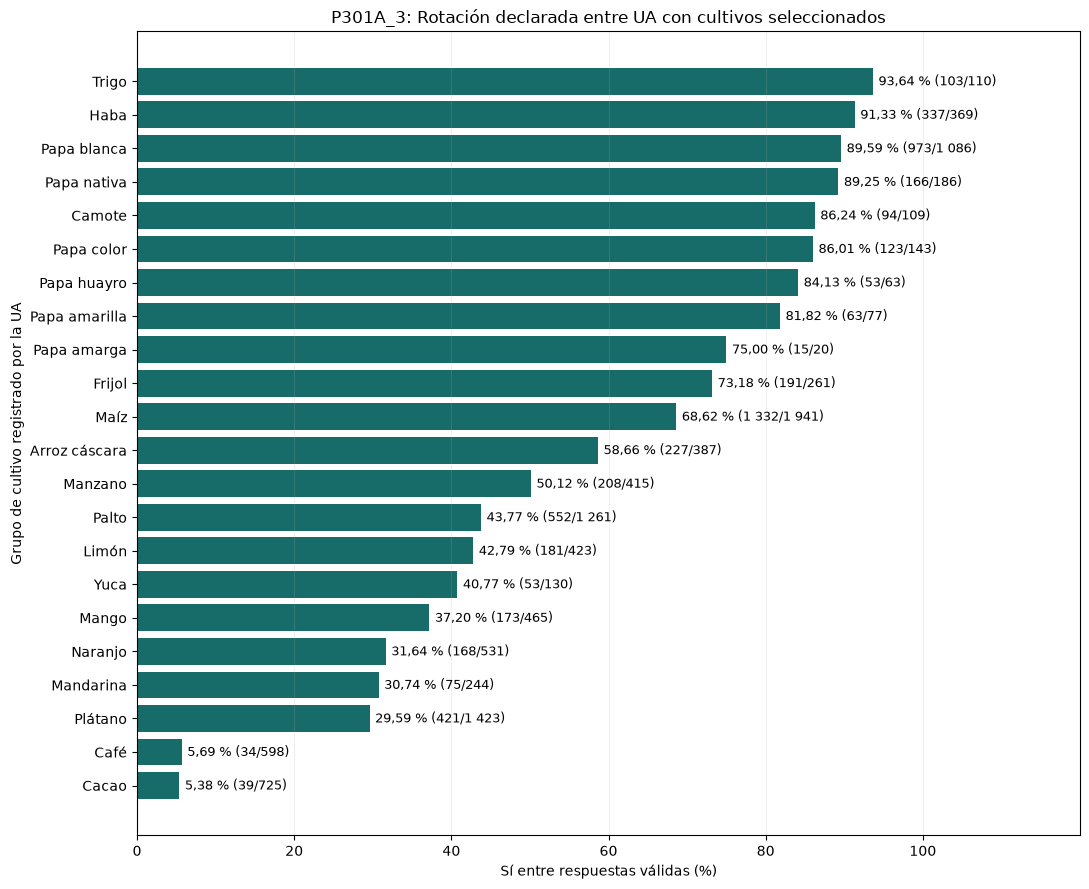

In [53]:
etiquetas_cultivo_aux = {"MAIZ": "Maíz", "FRIJOL": "Frijol", "HABA": "Haba", "CAFE": "Café",
                         "LIMON": "Limón", "PLATANO": "Plátano", "ARROZ CASCARA": "Arroz cáscara"}
grafico_cultivo_aux = tabla_rotacion_cultivo.loc[tabla_rotacion_cultivo["Total válido"].gt(0)].copy()
nombres_cultivo_aux = [etiquetas_cultivo_aux.get(c, c.capitalize()) for c in grafico_cultivo_aux.index]
plt.figure(figsize=(11, 9))
barras = plt.barh(nombres_cultivo_aux, grafico_cultivo_aux["Sí (%)"], color="#176B68")
plt.gca().invert_yaxis()
plt.title("P301A_3: Rotación declarada entre UA con cultivos seleccionados")
plt.xlabel("Sí entre respuestas válidas (%)")
plt.ylabel("Grupo de cultivo registrado por la UA")
plt.xlim(0, 120)
plt.xticks([0, 20, 40, 60, 80, 100])  # El espacio final permite leer las etiquetas.
plt.bar_label(barras, labels=[f"{p:.2f} % ({si:,}/{n:,})".replace(",", " ").replace(".", ",") for p, si, n in zip(
    grafico_cultivo_aux["Sí (%)"], grafico_cultivo_aux["Sí"], grafico_cultivo_aux["Total válido"])], padding=4, fontsize=9)
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

Entre las UA que registraron trigo, 103 de 110 (93,64 %) declararon rotar cultivos; entre las que registraron cacao, fueron 39 de 725 (5,38 %). Estas respuestas describen la práctica general de las UA, no demuestran que hayan rotado específicamente esos cultivos ni explican la diferencia. Las bases cambian entre grupos; papa amarga cuenta con solo 20 UA.

### 11.6. Rotación por categoría del periodo de cosecha

**Pregunta:** ¿Cómo cambia la rotación declarada entre UA que tienen alguna cosecha en cada categoría?

Complementa el cruce por cultivo con el contexto del periodo de cosecha, mas no mide el efecto de una duración sobre la rotación. P301A_3 utiliza `1=Sí` y `2 = No`. Una UA con varias cosechas puede integrar varias categorías. El denominador es el total válido de cada categoría; sin embargo, una categoría sin UA tiene un porcentaje no calculable.

In [54]:
elegibles_periodo_aux = pd.Series(True, index=ua_periodo_aux.index)
validas_periodo_aux = elegibles_periodo_aux & ua_periodo_aux["P301A_3"].isin([1, 2])
tabla_rotacion_periodo = pd.crosstab(
    ua_periodo_aux.loc[validas_periodo_aux, "categoria_cosecha"],
    ua_periodo_aux.loc[validas_periodo_aux, "P301A_3"]
).reindex(index=categorias_aux, columns=[1, 2], fill_value=0).rename(columns={1: "Sí", 2: "No"})
tabla_rotacion_periodo["UA elegibles"] = ua_periodo_aux.loc[elegibles_periodo_aux].groupby(
    "categoria_cosecha", observed=False).size().reindex(categorias_aux, fill_value=0)
tabla_rotacion_periodo["Total válido"] = tabla_rotacion_periodo["Sí"] + tabla_rotacion_periodo["No"]
tabla_rotacion_periodo["Sin respuesta válida"] = tabla_rotacion_periodo["UA elegibles"] - tabla_rotacion_periodo["Total válido"]
tabla_rotacion_periodo["Sí (%)"] = (100 * tabla_rotacion_periodo["Sí"] / tabla_rotacion_periodo["Total válido"].replace(0, float("nan"))).round(2)
tabla_rotacion_periodo = tabla_rotacion_periodo.rename_axis(index="Categoría de cosecha", columns=None)
print("Pertenencias UA-categoría no elegibles:", (~elegibles_periodo_aux).sum())
display(tabla_rotacion_periodo)

Pertenencias UA-categoría no elegibles: 0


,Sí,No,UA elegibles,Total válido,Sin respuesta válida,Sí (%)
Categoría de cosecha,,,,,,
Muy corto,2864,2042,4906,4906,0,58.38
Corto,135,538,673,673,0,20.06
Mediano,13,11,24,24,0,54.17
Largo,548,1470,2018,2018,0,27.16
Muy largo,0,0,0,0,0,NaN


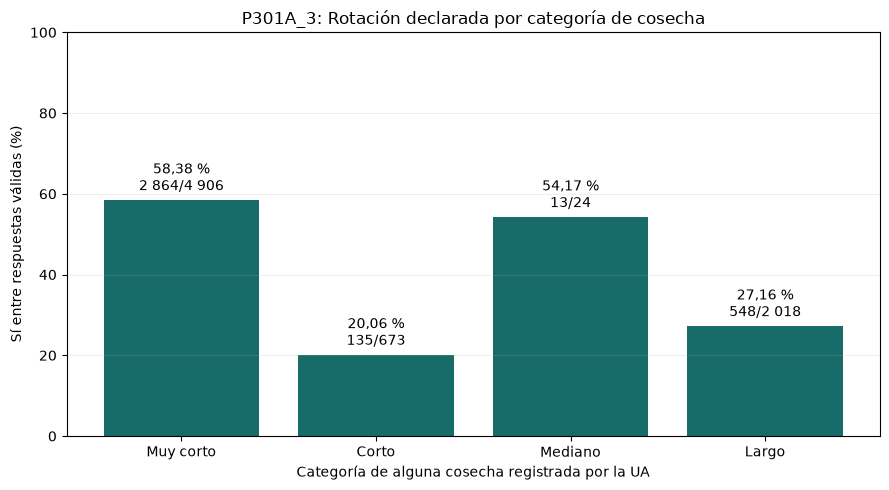

In [55]:
grafico_periodo_aux = tabla_rotacion_periodo.loc[tabla_rotacion_periodo["Total válido"].gt(0)]
plt.figure(figsize=(9, 5))
barras = plt.bar(grafico_periodo_aux.index.astype(str), grafico_periodo_aux["Sí (%)"], color="#176B68")
plt.title("P301A_3: Rotación declarada por categoría de cosecha")
plt.xlabel("Categoría de alguna cosecha registrada por la UA")
plt.ylabel("Sí entre respuestas válidas (%)")
plt.ylim(0, 100)
plt.bar_label(barras, labels=[f"{p:.2f} %\n{si:,}/{n:,}".replace(",", " ").replace(".", ",") for p, si, n in zip(
    grafico_periodo_aux["Sí (%)"], grafico_periodo_aux["Sí"], grafico_periodo_aux["Total válido"])], padding=4)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

UA vinculadas a cosechas de categoría `Muy corto` declararon rotar 2.864 de 4.906 (58,38 %) y 135 de 673 vinculadas a `Corto` (20,06 %).

La categoría `Mediano` tiene solo 24 UA; `Muy largo` no presenta casos. Considerando que los grupos pueden compartir UA y diferir en cultivos como también en territorios, sus diferencias no nos permiten necesariamente concluir que el periodo determine la rotación.

Se verifica una sola respuesta por UA dentro de cada categoría.

### 11.7. Rotación por departamento y grupo de cultivo

**Pregunta:** Entre las UA vinculadas a cada cultivo seleccionado, ¿cómo varía la proporción que declaró rotación entre los cinco departamentos?

`P301A_3` significa realizar rotación de cultivos para proteger el suelo (`1 = Sí`, `2 = No`). La unidad es una UA dentro de un grupo, no un registro de cosecha. La referencia general del grupo se añade con `transform("mean")`; la tabla muestra también la diferencia departamental en puntos porcentuales.

In [56]:
# Una UA por grupo y departamento, incorporando su respuesta del módulo 08.
ua_depto_cultivo = cultivos_aux[llave_aux + ["cultivo_grupo", "NOMBREDD"]].drop_duplicates()
ua_depto_cultivo = ua_depto_cultivo.merge(
    base_modulo_aux[llave_aux + ["P301A_3"]], on=llave_aux, how="inner", validate="many_to_one")
ua_depto_cultivo["Elegible"] = ua_depto_cultivo["P301A_3"].isin([1, 2])
ua_depto_cultivo["Rotación Sí"] = ua_depto_cultivo["P301A_3"].eq(1).where(ua_depto_cultivo["Elegible"])
ua_depto_cultivo["Referencia del cultivo (%)"] = (
    ua_depto_cultivo["Rotación Sí"].groupby(ua_depto_cultivo["cultivo_grupo"]).transform("mean") * 100)
tabla_rotacion_depto_cultivo = ua_depto_cultivo.groupby(
    ["cultivo_grupo", "NOMBREDD"]
).agg(**{"UA elegibles": ("P301A_3", "size")},
      **{"Total válido": ("Elegible", "sum")}, Sí=("Rotación Sí", "sum"),
      **{"Referencia del cultivo (%)": ("Referencia del cultivo (%)", "first")}).reset_index()
tabla_rotacion_depto_cultivo["Sin respuesta válida"] = tabla_rotacion_depto_cultivo["UA elegibles"] - tabla_rotacion_depto_cultivo["Total válido"]
tabla_rotacion_depto_cultivo["Sí (%)"] = 100 * tabla_rotacion_depto_cultivo["Sí"] / tabla_rotacion_depto_cultivo["Total válido"].replace(0, float("nan"))
tabla_rotacion_depto_cultivo["Diferencia vs. referencia (pp)"] = tabla_rotacion_depto_cultivo["Sí (%)"] - tabla_rotacion_depto_cultivo["Referencia del cultivo (%)"]
display(tabla_rotacion_depto_cultivo.round(2))

,cultivo_grupo,NOMBREDD,UA elegibles,Total válido,Sí,Referencia del cultivo (%),Sin respuesta válida,Sí (%),Diferencia vs. referencia (pp)
0,ARROZ CASCARA,AREQUIPA,230,230,215,58.66,0,93.48,34.82
1,ARROZ CASCARA,JUNIN,2,2,2,58.66,0,100.00,41.34
2,ARROZ CASCARA,SAN MARTIN,155,155,10,58.66,0,6.45,-52.20
3,CACAO,JUNIN,168,168,29,5.38,0,17.26,11.88
4,CACAO,SAN MARTIN,557,557,10,5.38,0,1.80,-3.58
...,...,...,...,...,...,...,...,...,...
82,YUCA,AREQUIPA,2,2,2,40.77,0,100.00,59.23
83,YUCA,ICA,7,7,4,40.77,0,57.14,16.37
84,YUCA,JUNIN,37,37,12,40.77,0,32.43,-8.34
85,YUCA,LIMA,36,36,31,40.77,0,86.11,45.34


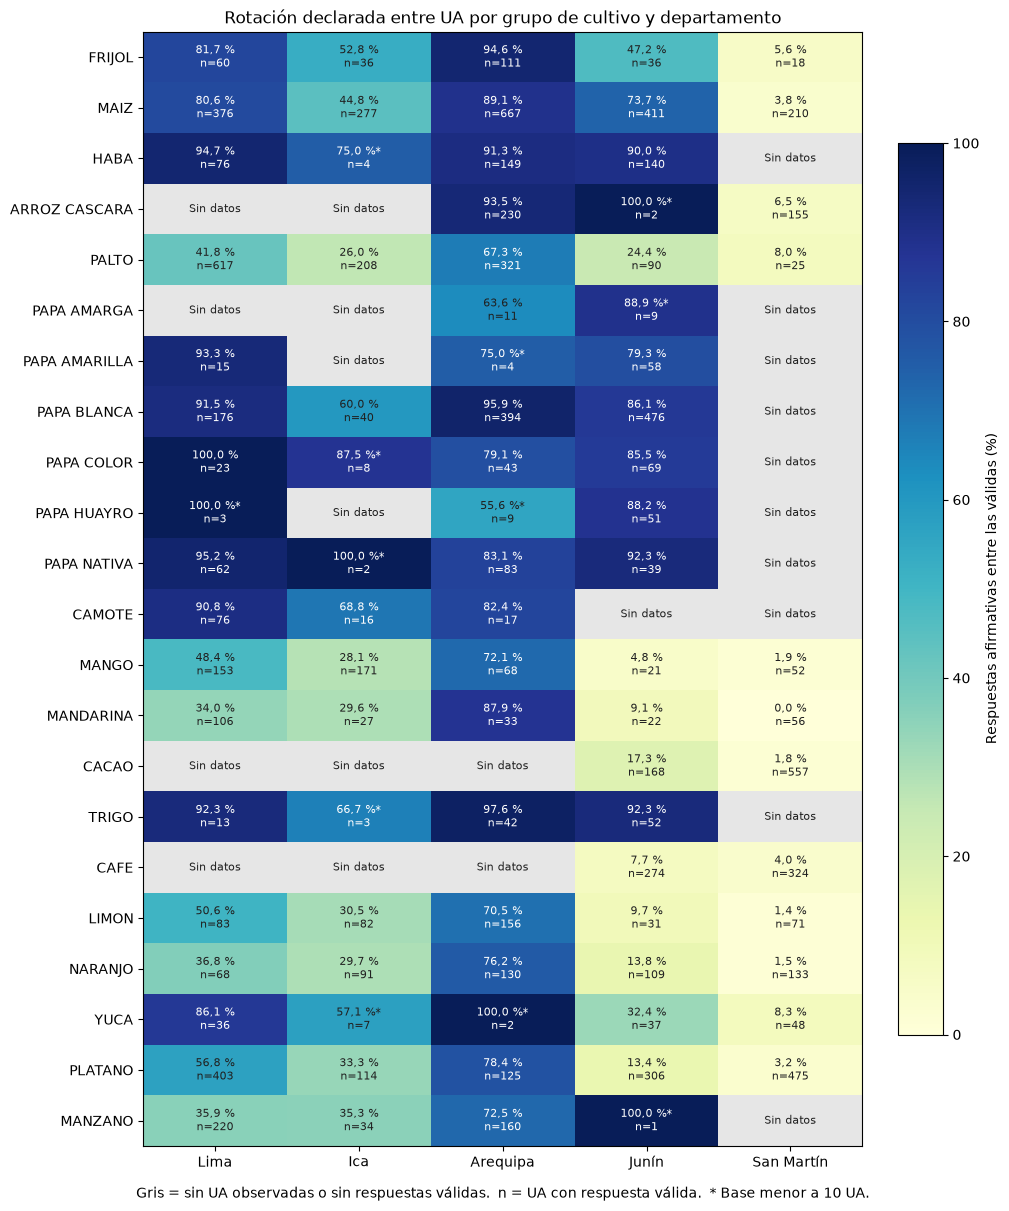

In [57]:
departamentos_mapa = ["LIMA", "ICA", "AREQUIPA", "JUNIN", "SAN MARTIN"]
porcentajes_mapa = tabla_rotacion_depto_cultivo.pivot(
    index="cultivo_grupo", columns="NOMBREDD", values="Sí (%)"
).reindex(index=grupos_aux, columns=departamentos_mapa)
bases_mapa = tabla_rotacion_depto_cultivo.pivot(
    index="cultivo_grupo", columns="NOMBREDD", values="Total válido"
).reindex_like(porcentajes_mapa)

fig, ax = plt.subplots(figsize=(10, 12), layout="constrained")
colores = plt.get_cmap("YlGnBu").with_extremes(bad="#e6e6e6")
imagen = ax.imshow(porcentajes_mapa, cmap=colores, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(departamentos_mapa)),
              ["Lima", "Ica", "Arequipa", "Junín", "San Martín"])
ax.set_yticks(range(len(grupos_aux)), grupos_aux)
ax.set_title("Rotación declarada entre UA por grupo de cultivo y departamento")
fig.colorbar(imagen, ax=ax, label="Respuestas afirmativas entre las válidas (%)", shrink=0.8)

for fila in range(len(grupos_aux)):
    for columna in range(len(departamentos_mapa)):
        porcentaje = porcentajes_mapa.iat[fila, columna]
        base = bases_mapa.iat[fila, columna]
        if pd.isna(base):
            etiqueta = "Sin datos"
        elif base == 0:
            etiqueta = "Sin válidas"
        else:
            marca = "*" if base < 10 else ""
            etiqueta = f"{porcentaje:.1f} %{marca}\nn={int(base)}".replace(".", ",")
        ax.text(columna, fila, etiqueta, ha="center", va="center", fontsize=8,
                color="white" if pd.notna(porcentaje) and porcentaje >= 65 else "#202020")

ax.set_xlabel("Gris = sin UA observadas o sin respuestas válidas.  "
              "n = UA con respuesta válida.  * Base menor a 10 UA.", labelpad=12)
plt.show()

Podemos observar que entre las UA vinculadas a `arroz cáscara`, declararon rotación 215 de 230 en `Arequipa` con un 93,5 % y 10 de 155 en San Martín con un 6,5 %.

Conservamos la referencia conjunta de cada grupo calculada con `transform("mean")` y las diferencias en puntos porcentuales. El mapa muestra los porcentajes departamentales de la práctica general declarada por la UA.

### 11.8. Incorporación de materia orgánica por grupo de cultivo

**Pregunta:** ¿Qué proporción de UA vinculadas a cada grupo declaró mezclar la tierra con materia orgánica?

`P301A_2` corresponde a mezclar tierra con rastrojos, estiércol, compost, humus u otros materiales orgánicos. Se cuentan respuestas válidas `1 = Sí` y `2 = No`; el denominador es su suma por grupo.

In [58]:
ua_organica = cultivos_aux[llave_aux + ["cultivo_grupo"]].drop_duplicates().merge(
    base_modulo_aux[llave_aux + ["P301A_2"]], on=llave_aux, how="inner", validate="many_to_one")
ua_organica["Elegible"] = ua_organica["P301A_2"].isin([1, 2])
respuestas_organica = ua_organica[ua_organica["Elegible"]]
tabla_organica_cultivo = pd.crosstab(respuestas_organica["cultivo_grupo"], respuestas_organica["P301A_2"]).reindex(
    index=grupos_aux, columns=[1, 2], fill_value=0).rename(columns={1:"Sí", 2:"No"})
tabla_organica_cultivo["UA elegibles"] = ua_organica.groupby("cultivo_grupo").size().reindex(grupos_aux, fill_value=0)
tabla_organica_cultivo["Total válido"] = tabla_organica_cultivo["Sí"] + tabla_organica_cultivo["No"]
tabla_organica_cultivo["Sin respuesta válida"] = tabla_organica_cultivo["UA elegibles"] - tabla_organica_cultivo["Total válido"]
tabla_organica_cultivo["Sí (%)"] = (100 * tabla_organica_cultivo["Sí"] / tabla_organica_cultivo["Total válido"].replace(0, float("nan"))).round(2)
display(tabla_organica_cultivo)

P301A_2,Sí,No,UA elegibles,Total válido,Sin respuesta válida,Sí (%)
cultivo_grupo,,,,,,
FRIJOL,167,94,261,261,0,63.98
MAIZ,1327,614,1941,1941,0,68.37
HABA,317,52,369,369,0,85.91
ARROZ CASCARA,166,221,387,387,0,42.89
PALTO,931,330,1261,1261,0,73.83
PAPA AMARGA,20,0,20,20,0,100.00
PAPA AMARILLA,60,17,77,77,0,77.92
PAPA BLANCA,896,190,1086,1086,0,82.50
PAPA COLOR,113,30,143,143,0,79.02


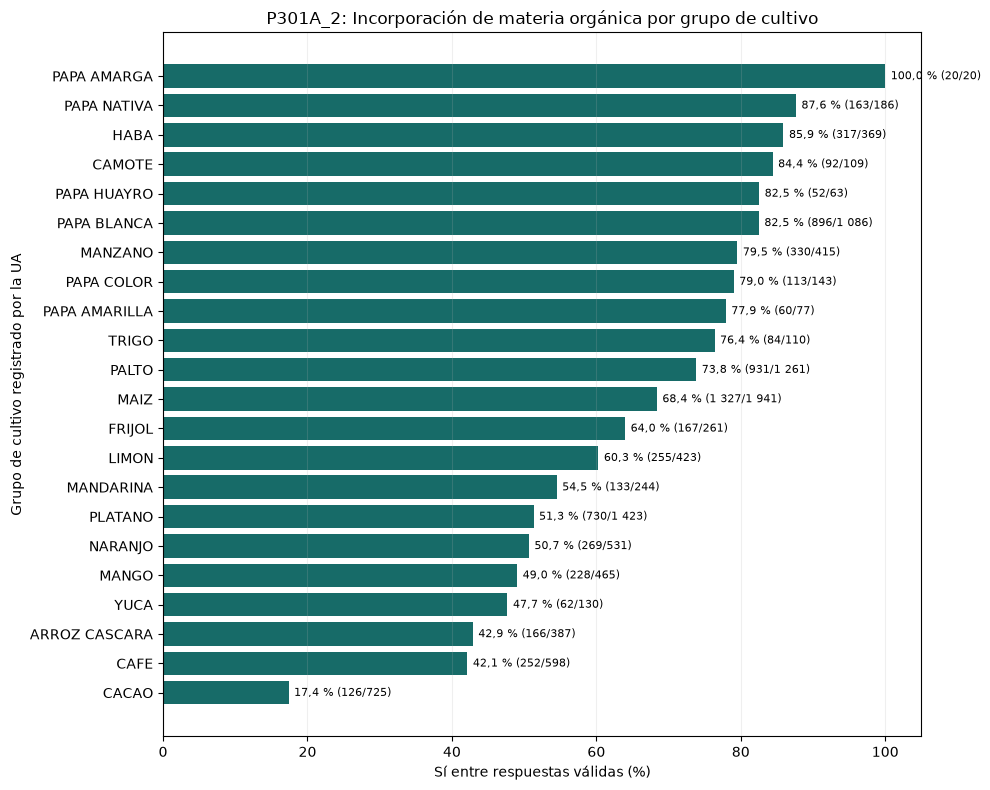

In [59]:
graf_organica = tabla_organica_cultivo[tabla_organica_cultivo["Total válido"].gt(0)].sort_values("Sí (%)")
plt.figure(figsize=(10, 8))
barras = plt.barh(graf_organica.index, graf_organica["Sí (%)"], color="#176B68")
plt.title("P301A_2: Incorporación de materia orgánica por grupo de cultivo")
plt.xlabel("Sí entre respuestas válidas (%)")
plt.ylabel("Grupo de cultivo registrado por la UA")
plt.bar_label(barras, labels=[f"{p:.1f} % ({s:,}/{n:,})".replace(",", " ").replace(".", ",") for p,s,n in zip(graf_organica["Sí (%)"], graf_organica["Sí"], graf_organica["Total válido"])], padding=4, fontsize=8)
plt.grid(axis="x", alpha=.2); plt.tight_layout(); plt.show()

La gráfica compara porcentajes y muestra el numerador y la base válida. Las UA pueden figurar en varios grupos; el cruce describe una práctica general de la unidad y no demuestra que se aplicara al cultivo indicado.

### 11.9. Uso combinado de fertilizantes y plaguicidas

**Pregunta:** ¿Qué combinaciones de uso declarado de fertilizantes y plaguicidas aparecen entre las UA vinculadas a los cultivos seleccionados?

`P301A_14` indica uso de fertilizantes y `P301A_15` uso de plaguicidas. Para no contar varias veces a una UA con varios cultivos, usamos una fila por UA distinta enlazada. Se incluyen sólo pares donde ambas respuestas son válidas (`1 = Sí`, `2 = No`); la tabla presenta frecuencias y  %  sobre pares completos.

In [60]:
# Uso combinado de fertilizantes y plaguicidas

ua_unica_seleccionada = cultivos_aux[llave_aux].drop_duplicates()
ua_insumos = ua_unica_seleccionada.merge(
    base_modulo_aux[llave_aux + ["P301A_14", "P301A_15"]],
    on=llave_aux, how="inner", validate="one_to_one"
)
pares_validos = ua_insumos[
    ua_insumos["P301A_14"].isin([1, 2]) & ua_insumos["P301A_15"].isin([1, 2])
].copy()

pares_validos["Fertilizantes"] = pares_validos["P301A_14"].map({1: "Sí", 2: "No"})
pares_validos["Plaguicidas"] = pares_validos["P301A_15"].map({1: "Sí", 2: "No"})

tabla_insumos = pd.crosstab(
    pares_validos["Fertilizantes"], pares_validos["Plaguicidas"]
).reindex(index=["Sí", "No"], columns=["Sí", "No"], fill_value=0)

tabla_insumos["Total"] = tabla_insumos.sum(axis=1)
tabla_insumos.loc["Total"] = tabla_insumos.sum(axis=0)

print("UA con ambas respuestas válidas:", len(pares_validos))
display(tabla_insumos)

UA con ambas respuestas válidas: 5897


Plaguicidas,Sí,No,Total
Fertilizantes,,,
Sí,4282,194,4476
No,496,925,1421
Total,4778,1119,5897


In [61]:
# Porcentaje de cada combinación

frecuencias_combinacion = (
    pares_validos.groupby(["Fertilizantes", "Plaguicidas"])
    .size().rename("UA").reset_index()
)
frecuencias_combinacion["Porcentaje"] = 100 * frecuencias_combinacion["UA"] / len(pares_validos)

display(frecuencias_combinacion.round(2))

,Fertilizantes,Plaguicidas,UA,Porcentaje
0,No,No,925,15.69
1,No,Sí,496,8.41
2,Sí,No,194,3.29
3,Sí,Sí,4282,72.61


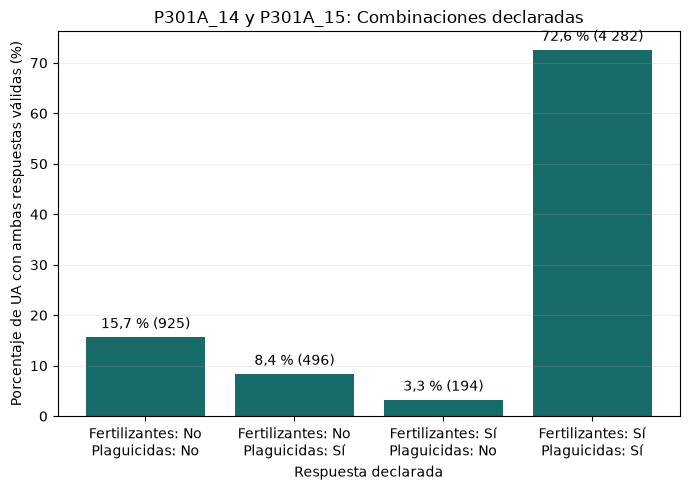

In [62]:
plt.figure(figsize=(7,5))
barras = plt.bar(frecuencias_combinacion.apply(lambda r: f"Fertilizantes: {r['Fertilizantes']}\nPlaguicidas: {r['Plaguicidas']}", axis=1), frecuencias_combinacion["Porcentaje"], color="#176B68")
plt.title("P301A_14 y P301A_15: Combinaciones declaradas")
plt.xlabel("Respuesta declarada")
plt.ylabel("Porcentaje de UA con ambas respuestas válidas (%)")
plt.bar_label(barras, labels=[f"{p:.1f} % ({n:,})".replace(",", " ").replace(".", ",") for p,n in zip(frecuencias_combinacion["Porcentaje"],frecuencias_combinacion["UA"])], padding=4)
plt.grid(axis="y", alpha=.2); plt.tight_layout(); plt.show()

La gráfica presenta las cuatro combinaciones posibles entre respuestas, con cantidades y porcentaje sobre UA con el par completo. Es una descripción conjunta; no permite concluir que un insumo cause el uso del otro ni que su utilización sea adecuada.